# BAI301 | RNN × Training Techniques
### Presentation-friendly Kaggle T4×2 notebook · IEEE-paper-ready outputs

**Muhammed Nehan & Ahmed Nagi — Ajman University, Fall 2026**  
**Instructor:** Dr. Omar Shalash  
**Architectures:** vanilla RNN, LSTM, GRU, Echo State Network (ESN)  
**Tasks:** Mackey–Glass chaos + Monash hourly electricity-load forecasting

> **Learning goal:** Understand what each model remembers; how gradient truncation, clipping and teacher forcing change learning; and whether the model that predicts one step best is also reliable for 100 future steps.

> **Scientific integrity:** This notebook computes results from real runs. It does not contain guessed accuracy scores or prefilled paper findings. The manuscript remains incomplete until the full experiment finishes and its statistical checks have been reviewed.

**What you will receive:** raw per-run JSON and training logs, train/validation/test provenance, CSV tables, plots, an ANOVA table, a validation-selected comparison of all four architectures, and an IEEE LaTeX results table. The notebook also archives its outputs for download.

### Two ways to run
1. **Full submission:** Open `BAI301_Kaggle_T4x2_FULL.ipynb`, enable **GPU T4 ×2** and **Internet ON**, and use **Run All**. The full grid may exceed a single Kaggle session: completed configurations are saved and skipped on rerun.
2. **Quick practice:** Open `BAI301_Kaggle_QUICKSTART.ipynb`. It runs the same code on a very small Mackey–Glass example without downloading electricity data. Learn/debug here first.

**Important:** Kaggle sessions have limits and outputs are not guaranteed to persist forever. Save a notebook version or download the results ZIP after each session. Upload the ZIP's extracted experiment directory back as an input if you need to resume in a fresh session.

## 0. Understand the entire research problem in five minutes

Imagine electricity usage over time. You know the last 100 readings. You must generate the next 100 without seeing any true future readings. A model can be good at predicting the next hour but terrible by hour 100 because it keeps feeding itself its own mistakes.

**Our research questions:**

- **RQ1: Rankings.** Is RNN, LSTM or GRU best under each training choice? Does an ESN compete with them?
- **RQ2: Long horizon.** Does the winner at step 1 remain the winner over 100 recursively forecast steps?
- **RQ3: Cost.** Is a more expensive training recipe worth the improvement in forecasting accuracy?
- **RQ4: Interactions.** Does the effect of truncation, clipping or forcing differ across architectures?

**What is new?** A complete controlled, cost-aware evaluation focused on rank changes and interactions. We do **not** claim the basic architectures, teacher forcing, long-horizon error or factorial comparisons were invented here. Closely related studies already exist.

**Coursework factors** (ESN is handled separately because its reservoir is not trained by gradient descent):

| Factor | Levels |
|:--|:--|
| Architecture | Vanilla RNN, LSTM, GRU, plus separate ESN |
| Truncated BPTT | 20 steps, 50 steps, full computation graph |
| Gradient clipping | Off or global gradient norm cap 1.0 |
| Teacher forcing | Always, scheduled sampling, never |
| Replication | 3 seeds: 42, 123, 2026 |
| Data | Mackey–Glass and electricity hourly |

**Full grid:** `3 × 3 × 2 × 3 × 3 × 2 = 324` gradient-trained runs, plus `2 datasets × 3 reservoir sizes × 3 seeds = 18` ESN runs, **excluding tuning trials**.

## 1. Beginner crash course: what are these models actually doing?

Let `x(t)` denote the current value, and `h(t)` an internal number/vector summarizing earlier observations.

**Vanilla RNN:** `h(t) = tanh(Wx·x(t) + Wh·h(t−1) + b)`. All time steps share the same learned weights. It remembers history through its hidden state, but repeated gradient multiplications can shrink or grow.

**LSTM (Long Short-Term Memory):** Adds a cell state `c(t)` and forget/input/output gates. One key equation is `c(t) = forget_gate × c(t−1) + input_gate × candidate_memory`. This additive route can preserve useful information longer.

**GRU (Gated Recurrent Unit):** Uses update and reset gates to manage memory, usually with fewer trainable parameters than an equally wide LSTM. We match **parameter count, not hidden width**, to avoid an unfair architecture comparison.

**ESN (Echo State Network):** A fixed, randomly connected recurrent *reservoir* processes observations. Only its linear output/readout is fitted using ridge regression. It doesn't use BPTT or clipping, so those factors are **not applicable** to ESN. Its reservoir size, leak, spectral radius and ridge penalty matter.

**TBPTT = Truncated Backpropagation Through Time:** The network may keep processing a long sequence, but gradients stop at designated chunk boundaries. We compare gradient horizons of 20, 50 and the full context-plus-rollout graph. We do **not** give short-chunk configurations extra optimizer updates.

**Gradient clipping:** If gradients become enormous, rescale them to cap their global norm at `1.0`. This guards against exploding gradients, but does not fix vanishing gradients.

**Teacher forcing:** After predicting the next value, the training loop can feed the **actual** previous target back (`always`), the **model's prediction** (`never`), or a controlled mixture (`scheduled`). During **validation and test, all models are free-running**: they only feed back their own predictions.

**Burn-in** is not an experimental factor in this coursework. Studying the amount of observation history needed to establish the recurrent state is a possible later research extension.

**Recommended quick reading:**
- Vizuara neural networks refresher: https://www.youtube.com/watch?v=CaFMTvAy38Q
- Vizuara RNNs: https://pods.vizuara.ai/courses/generative-ai-fundamentals-/recurrent-neural-networks-from-scratch
- Vizuara LSTM: https://pods.vizuara.ai/courses/foundations-of-machine-learning/all-about-lstm
- PyTorch GRU: https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html
- ReservoirPy ESN introduction: https://reservoirpy.readthedocs.io/en/stable/user_guide/quickstart.html

**Papers:** Johnston et al. (2025) `10.1016/j.neunet.2024.106887`; Shahi et al. (2022) `10.1016/j.mlwa.2022.100300`; Vlachas & Koumoutsakos (2024) `10.1016/j.physd.2024.134371`; Aicher et al. (2020) https://proceedings.mlr.press/v115/aicher20a.html; Schiller et al. (ICLR 2026) https://proceedings.iclr.cc/paper_files/paper/2026/hash/ac65e8b9360bca31d52656fa3f9693eb-Abstract-Conference.html

## 2. Kaggle hardware and dataset setup

In Kaggle Notebook Settings:
- **Accelerator → GPU T4 ×2**. Two separate GPUs, typically 16 GB each. We **run separate models on each GPU**, instead of making these small RNNs communicate across GPUs.
- **Internet → On** to fetch the public Monash electricity archive (11.8 MB).
- If Internet is disabled, upload `electricity_hourly_dataset.zip` from https://zenodo.org/records/4656140 using **Add Input → Upload dataset**.

The notebook uses **PyTorch, NumPy, pandas, SciPy, statsmodels, and matplotlib**. Kaggle usually has these pre-installed. For the optional ANOVA, install `statsmodels` if it is missing.

### Exact data rules
- Use chronological **70% train / 15% validation / 15% test** partitions; windows cannot cross a partition boundary.
- Normalize using the **training mean and standard deviation only**.
- Use **100 context observations** and forecast **100 subsequent steps**.
- Forecast origins are sampled with fixed strides. The training sample count is **capped at a predefined, evenly spaced subset** to keep the full factorial feasible; this must be disclosed in the paper.
- **Electricity** uses the sum of all available customer series after a documented causal missing-data policy; this is a **derived aggregate task**, not the official Monash per-customer benchmark.
- **Mackey–Glass** uses deterministic forward-Euler integration of the delay equation with a specified small time step, not the ReservoirPy generator. Cite the equation and report the numerical discretization honestly.

In [1]:
import os, sys, json, platform, importlib, subprocess, time, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown, FileLink, Image

KAGGLE = Path('/kaggle/working').exists()
PROJECT_DIR = (Path('/kaggle/working') if KAGGLE else Path.cwd()) / 'BAI301_Kaggle_Run'
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)
print('Work folder:', PROJECT_DIR)
print('PyTorch:',torch.__version__)
print('CUDA GPU count:',torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(' GPU',i,':',torch.cuda.get_device_name(i))
print('Operating system:',platform.platform())

Work folder: /kaggle/working/BAI301_Kaggle_Run
PyTorch: 2.11.0+cu130
CUDA GPU count: 2
 GPU 0 : Tesla T4
 GPU 1 : Tesla T4
Operating system: Linux-6.18.55+-x86_64-with-glibc2.39


## 3. Self-contained experiment engine

The next 22 short, explained code sections **write the complete source code** used to generate data, instantiate the architectures, train recurrent models, run ESNs, and record results. You do **not** need to download an external Python library or clone an unknown repository. The script is included inside this notebook.

**Key correctness feature:** For TBPTT, we detach both the recurrent hidden state and any model-generated feedback at chunk boundaries, but accumulate losses and take **only one optimizer update per whole minibatch**. This avoids accidentally giving short truncation settings more optimizer steps.

### How to read or present this code

Every section below has **one purpose**, a short plain-English explanation, and the exact Python implementation. The `%%writefile` magic starts the script; each `%%writefile -a` adds the next piece. **Run these cells in order.** You can remove the teaching notes later without changing the experiments.

The 22 small sections reproduce the *original Kaggle training engine*, including independent workers on `cuda:0` and `cuda:1`.

#### 4.1  Libraries, fixed seeds, and reproducibility

**What this code does:** Imports the numerical and deep-learning libraries and defines reproducibility helpers. Every experiment uses saved configuration values and a fixed seed.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [2]:
%%writefile experiment_engine.py
"""BAI301 Option B: self-contained reproducible RNN/ESN forecasting experiment engine.
Run with python experiment_engine.py --help. This is emitted inside the Kaggle notebook.
"""
from __future__ import annotations
import argparse, contextlib, csv, hashlib, io, itertools, json, math, os, random, re, resource, sys, time, traceback, warnings, zipfile
from dataclasses import dataclass
from pathlib import Path
from datetime import datetime
from urllib.request import urlopen, Request

import numpy as np
import pandas as pd
from scipy import sparse
from scipy.sparse.linalg import eigs
from scipy.linalg import solve as scipy_solve
import torch
from torch import nn
import psutil

SEEDS = [42, 123, 2026]
DATA_URL = 'https://zenodo.org/records/4656140/files/electricity_hourly_dataset.zip?download=1'
EXPECTED_MD5 = '18096614662b02640d265ad2a6a416bd'


def save_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + f'.{os.getpid()}.tmp')
    with open(tmp, 'w', encoding='utf-8') as f: json.dump(obj, f, indent=2, default=str, allow_nan=False)
    os.replace(tmp, path)


def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:16]


def file_md5(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for block in iter(lambda:f.read(1<<20), b''): h.update(block)
    return h.hexdigest()


def seed_all(seed, device='cpu'):
    random.seed(int(seed)); np.random.seed(int(seed)); torch.manual_seed(int(seed))
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(int(seed))
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.set_num_threads(1)




Writing experiment_engine.py


#### 4.2  Define the scientific experiment settings

**What this code does:** Central place for epochs, context length, forecast horizon, learning rates, dataset limits and ESN settings. Change the experiment here, not by editing model functions.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [3]:
%%writefile -a experiment_engine.py
def standard_config(preset='smoke', out_root='/kaggle/working/bai301_results'):
    cfg = dict(
        PRESET=preset, OUTPUT_ROOT=str(out_root), CONTEXT=100, HORIZON=100,
        DATASETS=['mg','electricity'] if preset=='full' else ['mg'],
        EPOCHS=30 if preset in ('full','minimum') else 2,
        BATCH_SIZE=64 if preset in ('full','minimum') else 8,
        RNN_HIDDEN=64 if preset in ('full','minimum') else 16,
        TRAIN_STRIDE=25, EVAL_STRIDE=100,
        MAX_TRAIN_ORIGINS=512 if preset in ('full','minimum') else 16,
        MAX_EVAL_ORIGINS=48 if preset in ('full','minimum') else 4,
        VALIDATE_EVERY=10 if preset in ('full','minimum') else 1,
        MG_N=50000 if preset in ('full','minimum') else 2500,
        MG_TRANSIENT=2000 if preset in ('full','minimum') else 500,
        MG_DT=0.1, MG_DELAY=17.0,
        LR_CANDIDATES=[0.0001,0.0003,0.001,0.003,0.01],
        TUNE_EPOCHS=3, TUNE_TRAIN_ORIGINS=128, TUNE_EVAL_ORIGINS=12,
        ESN_FIT_STATES=6000 if preset=='full' else 800,
        ESN_TUNE_EVAL_ORIGINS=12, ESN_WASHOUT=100,
        ESN_DENSITY=0.01, ESN_INPUT_SCALE=0.5,
        ESN_CANDIDATES=[
          {'rho':0.7,'leak':0.3,'ridge':1e-4},
          {'rho':0.9,'leak':0.5,'ridge':1e-4},
          {'rho':0.9,'leak':0.8,'ridge':1e-3},
          {'rho':1.05,'leak':0.3,'ridge':1e-3},
          {'rho':0.7,'leak':0.8,'ridge':1e-2}],
        ELECTRICITY_ZIP=None,
        RUN_TUNING=preset in ('full','minimum'),
    )
    return cfg


def run_directory(cfg):
    signature = {k:v for k,v in cfg.items() if k not in ('OUTPUT_ROOT','ELECTRICITY_ZIP')}
    return Path(cfg['OUTPUT_ROOT']) / ('exp_' + digest(signature))




Appending to experiment_engine.py


#### 4.3  Generate the Mackey–Glass time series

**What this code does:** Implements the delay differential equation numerically and returns a synthetic sequence. This provides a controlled chaotic forecasting problem.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [4]:
%%writefile -a experiment_engine.py
def generate_mackey_glass(n=50000, transient=2000, dt=0.1, tau=17., beta=.2, gamma=.1, power=10, x0=1.2):
    """Forward Euler integration of x' = beta*x(t-tau)/(1+x(t-tau)^n) - gamma*x(t).
    Output sampled every 1 time unit. This is a documented numeric approximation, NOT ReservoirPy.
    """
    stride=int(round(1/dt)); delay=int(round(tau/dt))
    assert abs(stride*dt-1)<1e-8 and abs(delay*dt-tau)<1e-8
    total=(n+transient)*stride
    states=np.full(total+delay+1, x0, dtype=np.float64)
    for i in range(delay, delay+total):
        old=states[i-delay]; now=states[i]
        states[i+1]=now+dt*(beta*old/(1+old**power)-gamma*now)
    return states[delay+1+transient*stride:delay+1+total:stride].astype('float32')[:n]




Appending to experiment_engine.py


#### 4.4  Download and verify the electricity archive

**What this code does:** Retrieves the published electricity dataset once, checks file integrity, and caches it. A local ZIP can be supplied when offline.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [5]:
%%writefile -a experiment_engine.py
def download_electricity_zip(dest, manual=None):
    dest=Path(dest); dest.parent.mkdir(parents=True, exist_ok=True)
    if manual:
        manual=Path(manual)
        if manual.is_file(): return manual
    if dest.exists() and zipfile.is_zipfile(dest): return dest
    # Kaggle Add Input -> inspect user-attached datasets first (internet may be disabled).
    for root in ('/kaggle/input',):
        if Path(root).exists():
            for p in Path(root).rglob('*electricity*hourly*.zip'):
                if zipfile.is_zipfile(p): return p
            for p in Path(root).rglob('*.tsf'):
                if 'electricity' in str(p).lower(): return p
    req=Request(DATA_URL, headers={'User-Agent':'BAI301 research experiment (student educational project)'})
    try:
        with urlopen(req,timeout=60) as resp, open(dest,'wb') as f:
            while True:
                chunk=resp.read(1024*1024)
                if not chunk: break
                f.write(chunk)
    except Exception as exc:
        dest.unlink(missing_ok=True)
        raise RuntimeError('Electricity download failed. In Kaggle turn Internet ON, or upload '
                           'electricity_hourly_dataset.zip using Add Input and rerun. '
                           f'Original error: {exc}') from exc
    if not zipfile.is_zipfile(dest):
        dest.unlink(missing_ok=True); raise RuntimeError('The electricity file was not a valid ZIP.')
    actual=file_md5(dest)
    if actual != EXPECTED_MD5:
        warnings.warn(f'Electricity archive MD5 differs from Zenodo version 3: {actual}; inspect source.')
    return dest




Appending to experiment_engine.py


#### 4.5  Read the TSF file

**What this code does:** Parses the time-series file format, including dates and missing observations, so real electricity records become numerical sequences.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [6]:
%%writefile -a experiment_engine.py
def extract_tsf_text(path):
    path=Path(path)
    if path.suffix.lower()=='.tsf': return path.read_text(encoding='utf-8-sig')
    with zipfile.ZipFile(path) as z:
        for name in z.namelist():
            if name.lower().endswith('.tsf'):
                return z.read(name).decode('utf-8-sig')
        for name in z.namelist():
            if name.lower().endswith('.zip'):
                with zipfile.ZipFile(io.BytesIO(z.read(name))) as sub:
                    for name2 in sub.namelist():
                        if name2.lower().endswith('.tsf'):
                            return sub.read(name2).decode('utf-8-sig')
    raise RuntimeError('Archive does not contain a .tsf file. Inspect its contents and source.')


def parse_tsf_records(text):
    records=[]; data_started=False
    for line in text.splitlines():
        line=line.strip()
        if not line or line.startswith('#'): continue
        if line.lower()=='@data': data_started=True; continue
        if not data_started or line.startswith('@'): continue
        # TSF format: metadata items separated by ':' then last item is comma-separated numbers.
        pieces=line.split(':')
        if len(pieces)<2: continue
        numbers=pieces[-1]
        vals=np.array([np.nan if x.strip() in ('?','') else float(x) for x in numbers.split(',')],dtype=np.float32)
        meta=pieces[:-1]
        stamp=None
        for item in meta:
            try:
                stamp=datetime.strptime(item.strip(),'%Y-%m-%d %H-%M-%S')
                break
            except ValueError: pass
        records.append((stamp, vals, meta[0] if meta else 'unknown'))
    if not records: raise RuntimeError('No time series found in the TSF file.')
    return records




Appending to experiment_engine.py


#### 4.6  Combine electricity readings into an hourly series

**What this code does:** Aligns customers in time and aggregates valid hourly readings, producing the real-data forecasting task used by all models.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [7]:
%%writefile -a experiment_engine.py
def aggregate_electricity(records):
    # Align by start time if available; do not assume all records begin simultaneously.
    starts=[r[0] for r in records]
    if all(s is not None for s in starts):
        start=min(starts)
        offsets=[int(round((s-start).total_seconds()/3600)) for s in starts]
        length=max(o+len(r[1]) for o,r in zip(offsets,records))
    else:
        if len({len(r[1]) for r in records}) != 1:
            raise ValueError('Cannot align unequal-length electricity series without timestamps.')
        if len({str(s) for s in starts}) != 1:
            raise ValueError('Some electricity start times are missing; cannot safely aggregate.')
        start=None; offsets=[0]*len(records); length=len(records[0][1])
    agg=np.zeros(length, dtype=np.float64)
    coverage=np.zeros(length,dtype=np.int32)
    for (stamp, vals, name),o in zip(records,offsets):
        # Causal missing-value treatment: forward fill once the series has begun,
        # and leading missing values become zero (documented, never backfill from future).
        cleaned=pd.Series(vals).ffill().fillna(0).to_numpy(dtype=np.float64)
        agg[o:o+len(vals)] += cleaned
        coverage[o:o+len(vals)] += 1
    if np.min(coverage)==0: raise RuntimeError('Aggregate series contains hours with no observed clients.')
    meta=dict(n_clients=len(records),hours=length,start_timestamp=str(start),
              client_coverage_min=int(coverage.min()),client_coverage_max=int(coverage.max()),
              client_coverage_changes=int(np.sum(np.diff(coverage)!=0)),
              missing_policy='Within client forward-fill, leading missing->0; not backfill')
    return agg.astype(np.float32),meta




Appending to experiment_engine.py


#### 4.7  Freeze the datasets and chronological splits

**What this code does:** Builds the saved train/validation/test partitions. Statistics for normalization come only from training data to avoid leakage.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [8]:
%%writefile -a experiment_engine.py
def prepare_data(cfg):
    root=run_directory(cfg); data=root/'data'; data.mkdir(parents=True,exist_ok=True)
    meta_path=data/'metadata.json'
    metadata=json.loads(meta_path.read_text()) if meta_path.exists() else {}
    for dataset in cfg['DATASETS']:
        output=data/(dataset+'.npy')
        if output.exists():
            values=np.load(output)
            metadata[dataset].update(n=len(values),sha256=hashlib.sha256(output.read_bytes()).hexdigest()) if dataset in metadata else metadata.update({dataset:dict(n=len(values),sha256=hashlib.sha256(output.read_bytes()).hexdigest(),cached=True)})
            continue
        if dataset=='mg':
            values=generate_mackey_glass(cfg['MG_N'],cfg['MG_TRANSIENT'],cfg['MG_DT'],cfg['MG_DELAY'])
            source_meta=dict(source='Mackey & Glass equation, documented forward Euler method',
                             dt=cfg['MG_DT'],delay=cfg['MG_DELAY'],beta=.2,gamma=.1,exponent=10,
                             transient_time_units=cfg['MG_TRANSIENT'])
        elif dataset=='electricity':
            archive=download_electricity_zip(data/'electricity_hourly_dataset.zip',cfg.get('ELECTRICITY_ZIP'))
            records=parse_tsf_records(extract_tsf_text(archive))
            values,source_meta=aggregate_electricity(records)
            source_meta.update(source='Zenodo 10.5281/zenodo.4656140, electricity hourly v3',
                               source_archive=str(archive),source_md5=file_md5(archive))
        else: raise ValueError(dataset)
        if not np.isfinite(values).all() or np.std(values)<1e-7:
            raise RuntimeError(f'{dataset}: invalid, missing, or nearly constant generated data')
        np.save(output,values)
        metadata[dataset]=dict(n=len(values),sha256=hashlib.sha256(output.read_bytes()).hexdigest(),**source_meta)
    save_json(meta_path,metadata)
    return metadata




Appending to experiment_engine.py


#### 4.8  Turn each time series into forecasting examples

**What this code does:** Creates windows of observed history and future target values. Every architecture sees the same windows and prediction horizons.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [9]:
%%writefile -a experiment_engine.py
class SeriesWindows:
    def __init__(self, values,cfg,split, max_origins=None,eval_mode=False):
        self.values=np.asarray(values, dtype=np.float32)
        n=len(self.values); boundaries=[0,int(n*.7),int(n*.85),n]
        a,b={'train':(boundaries[0],boundaries[1]),'val':(boundaries[1],boundaries[2]),
             'test':(boundaries[2],boundaries[3])}[split]
        self.a=a; self.b=b
        self.mean=float(np.mean(self.values[:boundaries[1]],dtype=np.float64))
        self.std=float(np.std(self.values[:boundaries[1]],dtype=np.float64))
        if self.std<=1e-9: raise ValueError('Near-zero training standard deviation')
        self.scaled=(self.values-self.mean)/self.std
        C,H=cfg['CONTEXT'],cfg['HORIZON']; stride=cfg['EVAL_STRIDE'] if eval_mode else cfg['TRAIN_STRIDE']
        # Context and target both inside the named chronological split. No split crossing.
        self.origins=np.arange(a,b-(C+H)+1,max(1,stride),dtype=np.int64)
        if len(self.origins)==0: raise RuntimeError(f'{split}: insufficient observations for C={C}, H={H}')
        cap=max_origins
        if cap is not None and len(self.origins)>cap:
            idx=np.linspace(0,len(self.origins)-1,cap,dtype=np.int64)
            self.origins=self.origins[idx]
        self.C=C;self.H=H

    def batches(self,batch_size,seed=42,shuffle=False):
        origins=self.origins.copy()
        if shuffle: np.random.default_rng(seed).shuffle(origins)
        offsets=np.arange(self.C+self.H,dtype=np.int64)
        for i in range(0,len(origins),batch_size):
            indices=origins[i:i+batch_size,None]+offsets[None,:]
            block=torch.from_numpy(np.ascontiguousarray(self.scaled[indices]))
            yield block[:,:self.C].unsqueeze(-1), block[:,self.C:].unsqueeze(-1)


def windows_for(cfg,dataset):
    series=np.load(run_directory(cfg)/'data'/(dataset+'.npy'))
    tr=SeriesWindows(series,cfg,'train',cfg['MAX_TRAIN_ORIGINS'])
    va=SeriesWindows(series,cfg,'val',cfg['MAX_EVAL_ORIGINS'],eval_mode=True)
    te=SeriesWindows(series,cfg,'test',cfg['MAX_EVAL_ORIGINS'],eval_mode=True)
    return tr,va,te




Appending to experiment_engine.py


#### 4.9  One forecaster class for RNN, LSTM and GRU

**What this code does:** The PyTorch architecture name is a switch, while the prediction head and autoregressive forecasting procedure remain common across models.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [10]:
%%writefile -a experiment_engine.py
class ForecastNet(nn.Module):
    def __init__(self,architecture,hidden_size):
        super().__init__(); layer={'RNN':nn.RNN,'LSTM':nn.LSTM,'GRU':nn.GRU}[architecture]
        self.architecture=architecture
        self.recurrent=layer(1,hidden_size,num_layers=1,batch_first=True)
        self.output_layer=nn.Linear(hidden_size,1)
        self.hidden_size=hidden_size
    def forward_inputs(self,inputs,state=None):
        hidden_seq, state=self.recurrent(inputs,state)
        return self.output_layer(hidden_seq[:,-1,:]),state
    def forward(self,context,targets=None,forcing='never',scheduled_prob=0.,rng=None):
        pred,state=self.forward_inputs(context)
        if targets is None:return pred,state
        predictions=[pred]; prev=pred
        for t in range(1,targets.shape[1]):
            if forcing=='always': feed=targets[:,t-1,:]
            elif forcing=='never': feed=prev
            else:
                mask=(torch.rand(prev.shape,device=prev.device,generator=rng)<scheduled_prob)
                feed=torch.where(mask,targets[:,t-1,:],prev)
            pred,state=self.forward_inputs(feed.unsqueeze(1),state)
            predictions.append(pred);prev=pred
        return torch.stack(predictions,dim=1),state




Appending to experiment_engine.py


#### 4.10  Match model sizes and manage hidden states

**What this code does:** Counts trainable parameters, chooses approximately comparable model capacities, and detaches hidden states where truncated gradients must stop.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [11]:
%%writefile -a experiment_engine.py
def params(model): return sum(x.numel() for x in model.parameters() if x.requires_grad)


def match_hidden_sizes(rnn_hidden):
    target=params(ForecastNet('RNN',rnn_hidden))
    options={'RNN':rnn_hidden}
    for arch in ('LSTM','GRU'):
        options[arch]=min(range(4,160),key=lambda h:abs(params(ForecastNet(arch,h))-target))
    return options


def detach_state(state):
    if state is None:return None
    return tuple(s.detach() for s in state) if isinstance(state,tuple) else state.detach()




Appending to experiment_engine.py


#### 4.11  Truncated Backpropagation Through Time (TBPTT)

**What this code does:** Handles full or truncated gradient propagation, gradient clipping and teacher-forcing feedback. The optimizer updates once per minibatch, keeping update counts comparable.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [12]:
%%writefile -a experiment_engine.py
def tbptt_batch(model,context,target,opt,chunk,clipping,forcing,teacher_probability,device,
                collect_grads=False):
    """Correct truncated BPTT: detach recurrent state *and predicted feedback* at
    chunk boundaries, use one optimizer step per entire C+H-1 example/minibatch.
    The context and rollout are in one time-line. All H losses are weighted 1/H.
    """
    C=context.shape[1]; H=target.shape[1]
    total_steps=C+H-1
    chunk=total_steps if chunk=='full' else int(chunk)
    state=None; last_pred=None; total_loss=0.
    opt.zero_grad(set_to_none=True)
    for start in range(0,total_steps,chunk):
        end=min(start+chunk,total_steps)
        losses=[]
        # Entirely loss-free context blocks need no gradient graph.
        no_losses=(end<C)
        with (torch.no_grad() if no_losses else contextlib.nullcontext()):
            t=start
            # Vectorize the observed context, stopping at t=C; no prediction targets
            # except the one at the final observed time t=C-1.
            if t<C:
                stop=min(end,C)
                inputs=context[:,t:stop,:]
                last_pred,state=model.forward_inputs(inputs,state)
                if stop==C:
                    losses.append(torch.square(last_pred-target[:,0,:]).mean()/H)
                t=stop
            while t<end:
                # t=C corresponds to feeding target[0] or predicted target[0],
                # then forecasting target[1].
                prev_true=target[:,t-C,:]
                if forcing=='always': feed=prev_true
                elif forcing=='never': feed=last_pred
                elif forcing=='scheduled':
                    mask=(torch.rand(last_pred.shape,device=device)<teacher_probability)
                    feed=torch.where(mask,prev_true,last_pred)
                else: raise ValueError(forcing)
                last_pred,state=model.forward_inputs(feed.unsqueeze(1),state)
                losses.append(torch.square(last_pred-target[:,t-C+1,:]).mean()/H)
                t+=1
        if losses:
            subloss=torch.stack(losses).sum()
            if not torch.isfinite(subloss):raise FloatingPointError('non-finite loss in training')
            subloss.backward()
            total_loss += float(subloss.detach().cpu())
        state=detach_state(state)
        if last_pred is not None: last_pred=last_pred.detach()
    # Gradient norms are recorded BEFORE clipping.
    preclip=float(torch.nn.utils.clip_grad_norm_(model.parameters(),float('inf')).item())
    if not math.isfinite(preclip):raise FloatingPointError('non-finite gradient norm')
    if clipping:
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
    opt.step()
    return total_loss,preclip




Appending to experiment_engine.py


#### 4.12  Predict and score without future-value leakage

**What this code does:** Runs free-running inference, times CUDA operations, calculates forecasting error, and establishes a simple no-training persistence benchmark.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [13]:
%%writefile -a experiment_engine.py
def pred_rollout(model,context,H):
    pred,state=model.forward_inputs(context)
    out=[pred]
    for _ in range(1,H):
        pred,state=model.forward_inputs(pred.unsqueeze(1),state)
        out.append(pred)
    return torch.stack(out,dim=1)


def gpu_sync(device):
    if str(device).startswith('cuda'): torch.cuda.synchronize(device)


def metrics_from_arrays(yhat, y, std):
    if not np.isfinite(yhat).all():raise FloatingPointError('non-finite forecast')
    delta=(yhat-y).astype(np.float64)
    H=delta.shape[1]
    r={'rmse_rollout':float(np.sqrt(np.mean(delta*delta))*std),
       'rmse_rollout_norm':float(np.sqrt(np.mean(delta*delta)))}
    for h in (1,20,50,100):
        if h<=H:r[f'rmse_{h}']=float(np.sqrt(np.mean(delta[:,h-1]**2))*std)
    return r

@torch.no_grad()
def eval_neural(model,ds,device,cfg,limit=None):
    model.eval(); targets=[]; predictions=[]
    for context,target in ds.batches(cfg['BATCH_SIZE'],seed=0,shuffle=False):
        context=context.to(device); target=target.to(device)
        p=pred_rollout(model,context,ds.H)
        targets.append(target.squeeze(-1).cpu().numpy())
        predictions.append(p.squeeze(-1).cpu().numpy())
    return metrics_from_arrays(np.concatenate(predictions),np.concatenate(targets),ds.std)


def persistence(ds):
    predictions=[];targets=[]
    for context,target in ds.batches(64):
        pred=context[:,-1:,0].numpy().repeat(ds.H,axis=1)
        predictions.append(pred);targets.append(target[:,:,0].numpy())
    return metrics_from_arrays(np.concatenate(predictions),np.concatenate(targets),ds.std)




Appending to experiment_engine.py


#### 4.13  Teacher-forcing schedule

**What this code does:** Controls the probability of using the real previous target rather than the model-generated prediction as input during training.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [14]:
%%writefile -a experiment_engine.py
def get_teacher_prob(forcing,epoch,epochs):
    if forcing=='always':return 1.
    if forcing=='never':return 0.
    return max(0.,1.-epoch/max(1,epochs-1))




Appending to experiment_engine.py


#### 4.14  Train and validate RNN / LSTM / GRU

**What this code does:** Runs the epoch loop, records gradients and runtime, evaluates with free-running forecasts, and retains validation/test metrics separately.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [15]:
%%writefile -a experiment_engine.py
def train_neural(cfg,info,device='cpu',tuning=False,lr=None):
    seed_all(info['seed'],device)
    tr,va,te=windows_for(cfg,info['dataset'])
    if tuning:
        tr.origins=tr.origins[np.linspace(0,len(tr.origins)-1,min(len(tr.origins),cfg['TUNE_TRAIN_ORIGINS']),dtype=np.int64)]
        va.origins=va.origins[:cfg['TUNE_EVAL_ORIGINS']]
    hidden=match_hidden_sizes(cfg['RNN_HIDDEN'])[info['architecture']]
    model=ForecastNet(info['architecture'],hidden).to(device)
    lr=float(lr if lr is not None else 0.001)
    opt=torch.optim.Adam(model.parameters(),lr=lr)
    n_epochs=cfg['TUNE_EPOCHS'] if tuning else cfg['EPOCHS']
    every=n_epochs if tuning else cfg['VALIDATE_EVERY']
    grad_norms=[]; history=[]; best_val=float('inf');best_state=None;best_epoch=None
    training_seconds=0.; wall_start=time.perf_counter(); n_updates=0
    time_to_train_mse_0_1=None
    if str(device).startswith('cuda'):torch.cuda.reset_peak_memory_stats(device)
    try:
        for ep in range(n_epochs):
            model.train(); epoch_losses=[]; this_norms=[]
            gpu_sync(device);start=time.perf_counter()
            for ctx,target in tr.batches(cfg['BATCH_SIZE'],seed=info['seed']+ep,shuffle=True):
                ctx,target=ctx.to(device),target.to(device)
                train_loss,gn=tbptt_batch(model,ctx,target,opt,info['tbptt'],info['clip'],
                                          info['forcing'],get_teacher_prob(info['forcing'],ep,n_epochs),device)
                epoch_losses.append(train_loss);this_norms.append(gn);n_updates+=1
            gpu_sync(device);epoch_seconds=time.perf_counter()-start
            training_seconds+=epoch_seconds
            grad_norms.extend(this_norms)
            rec={'epoch':ep+1,'train_epoch_seconds':float(epoch_seconds),
                 'mean_train_loss':float(np.mean(epoch_losses)),
                 'grad_norm_mean_preclip':float(np.mean(this_norms)),
                 'optimizer_updates_so_far':n_updates}
            if ((ep+1)%every==0) or ep==0 or ep+1==n_epochs:
                val=eval_neural(model,va,device,cfg)
                rec['val_rmse_rollout_norm']=val['rmse_rollout_norm']
                if val['rmse_rollout_norm']<best_val:
                    best_val=val['rmse_rollout_norm'];best_epoch=ep+1
                    best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            history.append(rec)
            if time_to_train_mse_0_1 is None and rec['mean_train_loss'] <= 0.1:
                time_to_train_mse_0_1=float(training_seconds)
        model.load_state_dict(best_state)
        val=eval_neural(model,va,device,cfg)
        result=dict(info,architecture=info['architecture'],seed=info['seed'],learning_rate=lr,
            hidden_size=hidden,trainable_parameters=params(model),best_epoch=best_epoch,
            train_origins=len(tr.origins),val_origins=len(va.origins),test_origins=len(te.origins),
            training_seconds=float(training_seconds),
            total_wall_seconds=float(time.perf_counter()-wall_start),
            gradient_norm_mean=float(np.mean(grad_norms)),
            gradient_norm_p95=float(np.percentile(grad_norms,95)),
            time_to_train_mse_0_1=time_to_train_mse_0_1,
            optimizer_updates=int(n_updates),diverged=False,
            peak_gpu_memory_mb=(float(torch.cuda.max_memory_allocated(device)/2**20)
                               if str(device).startswith('cuda') else None),
            peak_cpu_rss_mb=None,status='ok')
        result.update({'val_'+k:v for k,v in val.items()})
        if not tuning:
            test=eval_neural(model,te,device,cfg)
            result.update({'test_'+k:v for k,v in test.items()})
        return result,history
    finally:
        del model
        if str(device).startswith('cuda'): torch.cuda.empty_cache()




Appending to experiment_engine.py


#### 4.15  Prepare the ESN reservoir weights

**What this code does:** Scales the spectral radius of a sparse fixed recurrent matrix. This is one hyperparameter of the reservoir, not a learned weight update.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [16]:
%%writefile -a experiment_engine.py
def esn_spectral_rescale(W,rho):
    # Radius approx via ARPACK (nonsymmetric sparse W). Fallback uses power iteration
    # only if ARPACK cannot converge; record fallback in metadata if needed.
    try:
        ev=eigs(W,k=1,which='LM',return_eigenvectors=False,maxiter=600,tol=.02)
        radius=float(np.max(np.abs(ev)))
    except Exception:
        v=np.random.default_rng(0).normal(size=W.shape[0])
        for _ in range(75):
            v=W@v
            v=v/(np.linalg.norm(v)+1e-12)
        radius=float(np.linalg.norm(W@v))
    if radius<1e-9:raise RuntimeError('Reservoir spectral radius nearly zero')
    return (W*(rho/radius)).tocsr()




Appending to experiment_engine.py


#### 4.16  Define the Echo State Network (ESN)

**What this code does:** Unlike the other three architectures, the reservoir is fixed; ridge regression fits the output readout, which is why ESN is evaluated separately.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [17]:
%%writefile -a experiment_engine.py
class EchoState:
    def __init__(self,size,seed,params,cfg):
        self.size=int(size); self.leak=float(params['leak']);self.ridge=float(params['ridge'])
        rng=np.random.default_rng(seed)
        self.win=rng.uniform(-cfg['ESN_INPUT_SCALE'],cfg['ESN_INPUT_SCALE'],size=(self.size,)).astype(np.float64)
        self.bias=rng.uniform(-.1,.1,size=(self.size,)).astype(np.float64)
        density=float(cfg['ESN_DENSITY'])
        self.W=sparse.random(self.size,self.size,density=density,format='csr',random_state=seed,
            data_rvs=lambda s:rng.uniform(-1,1,size=s))
        self.W=esn_spectral_rescale(self.W,float(params['rho']))
        self.beta=None
    def step(self,x,state):
        return (1-self.leak)*state+self.leak*np.tanh(self.W@state+self.win*float(x)+self.bias)
    def features(self,x,state):
        return np.concatenate(([1.,float(x)],state))
    def fit(self,series_scaled,train_end,max_states,washout):
        n=int(train_end); idx=np.arange(max(washout,1),n-1,dtype=np.int64)
        if len(idx)>max_states:
            idx=idx[np.linspace(0,len(idx)-1,max_states,dtype=np.int64)]
        feat=np.empty((len(idx),self.size+2),dtype=np.float64)
        y=np.empty((len(idx),),dtype=np.float64)
        r=np.zeros(self.size,dtype=np.float64); p=0
        for t in range(n-1):
            x=float(series_scaled[t]);r=self.step(x,r)
            if p<len(idx) and t==idx[p]:
                feat[p]=self.features(x,r);y[p]=series_scaled[t+1];p+=1
        assert p==len(idx)
        # Normal equations + regularization (stable solve with conditioning check).
        gram=feat.T@feat
        gram.flat[::gram.shape[0]+1] += self.ridge
        self.beta=scipy_solve(gram,feat.T@y,assume_a='pos',check_finite=False)
        return len(idx)
    def predict_window(self,context,H):
        state=np.zeros(self.size,dtype=np.float64)
        for value in context:state=self.step(value,state)
        last=float(context[-1]);out=np.empty(H,dtype=np.float64)
        for j in range(H):
            guess=float(self.features(last,state)@self.beta)
            if not math.isfinite(guess):raise FloatingPointError('ESN predictions non-finite')
            out[j]=guess
            last=guess
            if j<H-1:state=self.step(last,state)
        return out




Appending to experiment_engine.py


#### 4.17  Evaluate and fit the ESN baseline

**What this code does:** Fits and evaluates reservoir forecasting using the same held-out windows, while logging CPU-side training cost separately from GPU training.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [18]:
%%writefile -a experiment_engine.py
def eval_esn(model,ds):
    preds=[];targets=[]
    for context,target in ds.batches(16):
        cx=context.squeeze(-1).numpy();y=target.squeeze(-1).numpy()
        p=np.stack([model.predict_window(row,ds.H) for row in cx])
        preds.append(p);targets.append(y)
    return metrics_from_arrays(np.concatenate(preds),np.concatenate(targets),ds.std)


def train_esn(cfg,info,tuning=False,params=None):
    seed_all(info['seed'])
    tr,va,te=windows_for(cfg,info['dataset'])
    if tuning:va.origins=va.origins[:cfg['ESN_TUNE_EVAL_ORIGINS']]
    series=tr.scaled
    if params is None:params=cfg['ESN_CANDIDATES'][1]
    wall=time.perf_counter()
    model=EchoState(info['esn_size'],info['seed'],params,cfg)
    train_start=time.perf_counter()
    nstates=model.fit(series,tr.b,min(cfg['ESN_FIT_STATES'],tr.b-2),cfg['ESN_WASHOUT'])
    train_seconds=time.perf_counter()-train_start
    val=eval_esn(model,va)
    result=dict(info,status='ok',diverged=False,esn_fit_states=nstates,
                esn_spectral_radius_target=params['rho'],esn_leak=params['leak'],
                esn_ridge=params['ridge'],trainable_parameters=info['esn_size']+2,
                total_wall_seconds=time.perf_counter()-wall,
                training_seconds=train_seconds,
                cpu_rss_postfit_mb=float(psutil.Process().memory_info().rss/2**20),
                peak_cpu_rss_mb=float(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1024.0),
                peak_gpu_memory_mb=None,gradient_norm_mean=None,gradient_norm_p95=None,
                optimizer_updates=1,train_origins=nstates,val_origins=len(va.origins),
                test_origins=len(te.origins))
    result.update({'val_'+k:v for k,v in val.items()})
    if not tuning:
        test=eval_esn(model,te)
        result.update({'test_'+k:v for k,v in test.items()})
    return result,[]




Appending to experiment_engine.py


#### 4.18  Generate the full experimental grid

**What this code does:** Lists all combinations of models, truncation, clipping, forcing and seeds. The ESN sweep is added as a separate family of runs.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [19]:
%%writefile -a experiment_engine.py
def experiment_grid(cfg):
    preset=cfg['PRESET']
    if preset=='smoke':
        specs=[dict(dataset='mg',architecture=a,tbptt=20,clip=True,forcing='always',seed=42)
               for a in ('RNN','LSTM','GRU')]
        specs.append(dict(dataset='mg',architecture='ESN',esn_size=200,seed=42))
        return specs
    if preset=='minimum':
        datasets=['mg'];chunks=[20,50];forcing=['always','scheduled']
    else:
        datasets=cfg['DATASETS'];chunks=[20,50,'full'];forcing=['always','scheduled','never']
    specs=[dict(dataset=d,architecture=a,tbptt=k,clip=bool(c),forcing=f,seed=s)
           for d,a,k,c,f,s in itertools.product(datasets,['RNN','LSTM','GRU'],chunks,[0,1],forcing,SEEDS)]
    specs += [dict(dataset=d,architecture='ESN',esn_size=z,seed=s)
              for d,z,s in itertools.product(datasets,[200,500,1000],SEEDS)]
    return specs




Appending to experiment_engine.py


#### 4.19  Tune hyperparameters on validation data only

**What this code does:** Selects learning rate or reservoir settings without looking at the test set. The tuning budget is the same across the trainable model families.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [20]:
%%writefile -a experiment_engine.py
def tuning_grid(cfg):
    if cfg['PRESET']=='smoke' or not cfg['RUN_TUNING']:return []
    return [(d,a) for d,a in itertools.product(cfg['DATASETS'],['RNN','LSTM','GRU','ESN'])]


def tuning_path(cfg,dataset,arch):return run_directory(cfg)/'tuning'/f'{dataset}_{arch}.json'


def do_tune(cfg,dataset,arch,device):
    path=tuning_path(cfg,dataset,arch)
    if path.exists(): return
    if arch=='ESN':
        trials=[]
        for p in cfg['ESN_CANDIDATES']:
            try:
                obj,_=train_esn(cfg,dict(dataset=dataset,architecture='ESN',esn_size=200,seed=42),True,p)
                trials.append(dict(params=p,score=obj['val_rmse_rollout_norm'],seconds=obj['total_wall_seconds']))
            except Exception as e:trials.append(dict(params=p,score=None,error=str(e)))
        good=[r for r in trials if r['score'] is not None]
        if not good:raise RuntimeError(f'ESN tuning failed: {trials}')
        best=min(good,key=lambda r:r['score'])
        save_json(path,dict(dataset=dataset,arch=arch,selection='validation free-running RMSE',
                            trials=trials,chosen_params=best['params']))
    else:
        trials=[]
        for lr in cfg['LR_CANDIDATES']:
            try:
                info=dict(dataset=dataset,architecture=arch,tbptt=50,clip=True,forcing='always',seed=42)
                obj,_=train_neural(cfg,info,device,True,lr)
                trials.append(dict(lr=lr,score=obj['val_rmse_rollout_norm'],seconds=obj['total_wall_seconds']))
            except Exception as e:trials.append(dict(lr=lr,score=None,error=str(e)))
        good=[r for r in trials if r['score'] is not None]
        if not good:raise RuntimeError(f'LR tuning failed: {trials}')
        best=min(good,key=lambda r:r['score'])
        save_json(path,dict(dataset=dataset,arch=arch,selection='validation free-running RMSE',
                            trials=trials,chosen_lr=best['lr']))




Appending to experiment_engine.py


#### 4.20  Resume-safe experiment runner

**What this code does:** Executes independent configurations, saves every result and failure to disk, and skips completed runs when restarting the notebook.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [21]:
%%writefile -a experiment_engine.py
def execute_worker(cfg,worker_id,n_workers,device,mode):
    root=run_directory(cfg)
    if mode=='tune':
        tasks=tuning_grid(cfg)
        for i, (d,a) in enumerate(tasks):
            if i%n_workers!=worker_id:continue
            print(f'[worker {worker_id}] tuning {d}/{a}',flush=True)
            do_tune(cfg,d,a,device)
        return
    tasks=experiment_grid(cfg)
    for i,info in enumerate(tasks):
        if i%n_workers!=worker_id:continue
        key=digest(info)
        out=root/'runs'/(key+'.json')
        if out.exists():
            try:
                existing=json.loads(out.read_text())
                if existing.get('status')=='ok':continue
            except Exception:pass
        print(f'[worker {worker_id}] {i+1}/{len(tasks)} {info}',flush=True)
        wall=time.perf_counter(); hist=[]
        try:
            path=tuning_path(cfg,info['dataset'],info['architecture'])
            hyper=json.loads(path.read_text()) if path.exists() else {}
            if info['architecture']=='ESN':
                result,hist=train_esn(cfg,info,False,hyper.get('chosen_params'))
            else:
                result,hist=train_neural(cfg,info,device,False,hyper.get('chosen_lr',.001))
            result['run_key']=key
        except Exception as e:
            result={**info,'status':'failed','diverged':True,'run_key':key,
                    'total_wall_seconds':time.perf_counter()-wall,
                    'error':repr(e),'traceback':traceback.format_exc(limit=8)}
        save_json(out,result)
        if hist:
            save_json(root/'epochs'/(key+'.json'),hist)
        if result['status']!='ok':print(f"[worker {worker_id}] FAILED: {result['error']}",flush=True)
    print(f'[worker {worker_id}] done',flush=True)




Appending to experiment_engine.py


#### 4.21  Research-code correctness checks

**What this code does:** Tests recurrent-state shapes, teacher-forcing leakage, full versus truncated gradient equivalence, reproducibility and data parsing.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [22]:
%%writefile -a experiment_engine.py
def self_tests():
    # Shapes, matching first step, full-vs-long-chunk, TBPTT gradient detachment,
    # equal optimizer update counts, and forecast independence of future targets.
    seed_all(42)
    torch.set_num_threads(1)
    C,H=6,5; x=torch.randn(3,C,1);y=torch.randn(3,H,1)
    for arch in ['RNN','LSTM','GRU']:
        m=ForecastNet(arch,8)
        pred,st=m.forward_inputs(x)
        assert pred.shape==(3,1)
        if arch=='LSTM':assert isinstance(st,tuple) and len(st)==2
        with torch.no_grad():
            teacher,_=m(x,y,'always'); free,_=m(x,y,'never')
        assert torch.allclose(teacher[:,0],free[:,0],atol=1e-7)
        assert not torch.isnan(teacher).any()
        # first prediction is unaffected by any future target perturbation
        with torch.no_grad():
            teacher2,_=m(x,y*10000,'always')
        assert torch.allclose(teacher[:,0],teacher2[:,0],atol=1e-7)
        # Full BPTT equals non-truncated chunk >= graph length.
        m1=ForecastNet(arch,8);m2=ForecastNet(arch,8);m2.load_state_dict(m1.state_dict())
        o1=torch.optim.SGD(m1.parameters(),lr=.01);o2=torch.optim.SGD(m2.parameters(),lr=.01)
        l1,g1=tbptt_batch(m1,x,y,o1,'full',False,'always',1.,'cpu')
        l2,g2=tbptt_batch(m2,x,y,o2,C+H+10,False,'always',1.,'cpu')
        assert abs(l1-l2)<1e-6 and abs(g1-g2)<1e-5
        assert all(torch.allclose(p,q,atol=1e-6) for p,q in zip(m1.parameters(),m2.parameters()))
        # With a short chunk, one step still occurs per minibatch (not per chunk).
        m3=ForecastNet(arch,8);m3.load_state_dict(m1.state_dict())
        o3=torch.optim.SGD(m3.parameters(),lr=.01)
        l3,g3=tbptt_batch(m3,x,y,o3,2,True,'scheduled',.5,'cpu')
        assert math.isfinite(l3)
    # Synthetic MG should be nonlinear, reproducible, and finite.
    a=generate_mackey_glass(400,transient=100)
    b=generate_mackey_glass(400,transient=100)
    assert len(a)==400 and np.isfinite(a).all() and np.array_equal(a,b) and np.std(a)>1e-3
    # Test a miniature TSF parser with staggered starts and missing observations.
    txt='@attribute series_name string\n@attribute start_timestamp date\n@data\nA:2012-01-01 00-00-00:1,2,3\nB:2012-01-01 01-00-00:2,?,4'
    ag,meta=aggregate_electricity(parse_tsf_records(txt))
    assert len(ag)==4 and np.allclose(ag,[1,4,5,4])
    return 'PASS: RNN/LSTM/GRU tensor shapes, leakage, full-BPTT identity, TBPTT updates, MG and TSF parsing'




Appending to experiment_engine.py


#### 4.22  Command-line entry point

**What this code does:** Connects this module to the notebook and Windows scripts; it supports preparation, tuning, training and testing.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [23]:
%%writefile -a experiment_engine.py
def main():
    p=argparse.ArgumentParser()
    p.add_argument('--config',required=True)
    p.add_argument('--mode',choices=['prepare','tune','run','test'],default='run')
    p.add_argument('--worker-id',type=int,default=0)
    p.add_argument('--workers',type=int,default=1)
    p.add_argument('--device',default='cpu')
    args=p.parse_args()
    cfg=json.loads(Path(args.config).read_text())
    if args.mode=='test': print(self_tests());return
    if args.mode=='prepare':print('DATA:',prepare_data(cfg));return
    execute_worker(cfg,args.worker_id,args.workers,args.device,args.mode)

if __name__=='__main__':main()


Appending to experiment_engine.py


## 4. Automatic paper analysis

The next 15 explained sections write a second included script. It loads the actual per-run JSON files, retains failed runs, selects the best configuration **using validation data**, runs a full factorial ANOVA only when the grid is complete, and writes CSV/PNG/IEEE-LaTeX outputs.

**Never infer outcomes from an incomplete grid**. The analysis explicitly says if ANOVA or three-seed selection is not yet valid.

#### 5.1  Reporting imports and IEEE formatting

**What this code does:** Loads pandas/Matplotlib and shared data functions. Keeps report generation separate from the training code.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [24]:
%%writefile analysis_report.py
"""Generate honest, source-backed experiment results, figures, ANOVA and IEEE tables.
Never fills missing results with fake measurements. Partial runs are labelled partial.
"""
from __future__ import annotations
import json, math, os, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from experiment_engine import run_directory, experiment_grid, windows_for, persistence




Writing analysis_report.py


#### 5.2  Read saved run results

**What this code does:** Loads the experiment results already written to disk; it does not invent or estimate missing values.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [25]:
%%writefile -a analysis_report.py
def latex_escape(s):
    return str(s).replace('\\','\\textbackslash{}').replace('_','\\_').replace('%','\\%').replace('&','\\&')


def load_results(cfg):
    root=run_directory(cfg); rows=[]
    for path in sorted((root/'runs').glob('*.json')):
        data=json.loads(path.read_text()); rows.append(data)
    return pd.DataFrame(rows)




Appending to analysis_report.py


#### 5.3  Select fair, three-seed neural-model comparisons

**What this code does:** Groups configurations and selects winning settings using validation results only, while keeping seed variability visible.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [26]:
%%writefile -a analysis_report.py
def aggregate_paired(df):
    # Dataframe from completed runs only, primary comparisons from validation-selected
    # group; seeds remain statistical replicates instead of treating forecast steps as IID.
    keys=['dataset','architecture','tbptt','clip','forcing']
    neural=df[(df.architecture!='ESN')&(df.status=='ok')].copy()
    if neural.empty:return pd.DataFrame(),pd.DataFrame()
    val=neural.groupby(keys,dropna=False).agg(
        val_mean=('val_rmse_rollout_norm','mean'), val_std=('val_rmse_rollout_norm','std'),
        seeds=('seed','nunique')).reset_index()
    # Only preselected groups with all three seeds are eligible for selected-model claims.
    qualified=val[val.seeds==3]
    if qualified.empty:return val,pd.DataFrame()
    winners=qualified.sort_values(['dataset','architecture','val_mean']).groupby(['dataset','architecture']).head(1)
    chosen=neural.merge(winners[keys],on=keys,how='inner')
    rows=[]
    for (d,a),g in chosen.groupby(['dataset','architecture']):
        row={'dataset':d,'architecture':a,'tbptt':str(g.tbptt.iloc[0]),
             'clip':bool(g['clip'].iloc[0]),'forcing':g.forcing.iloc[0], 'seeds':int(g.seed.nunique())}
        for metric in ('test_rmse_1','test_rmse_20','test_rmse_50','test_rmse_100',
                       'test_rmse_rollout','test_rmse_rollout_norm','training_seconds',
                       'peak_gpu_memory_mb','gradient_norm_mean'):
            if metric in g:
                row[metric+'_mean']=float(g[metric].mean())
                row[metric+'_sd']=float(g[metric].std())
        rows.append(row)
    return val,pd.DataFrame(rows)




Appending to analysis_report.py


#### 5.4  Test whether training factors interact

**What this code does:** Runs a four-factor ANOVA only for a complete factorial dataset. An incomplete grid is reported as incomplete instead of given a misleading p-value.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [27]:
%%writefile -a analysis_report.py
def anova_tables(df,root,cfg):
    out=[]
    try:
        from statsmodels.formula.api import ols
        from statsmodels.stats.anova import anova_lm
    except Exception as e:
        return pd.DataFrame([{'status':'statsmodels unavailable','reason':str(e)}])
    for name,g in df[(df.status=='ok') & (df.architecture!='ESN')].groupby('dataset'):
        # Reject incomplete factorial grid for full ANOVA; show incompleteness clearly.
        expected={ (i['architecture'],str(i['tbptt']),str(i['clip']),i['forcing'],int(i['seed']))
                   for i in experiment_grid(cfg) if i['dataset']==name and i['architecture']!='ESN'}
        got={ (r.architecture,str(r.tbptt),str(r['clip']),r.forcing,int(r.seed)) for _,r in g.iterrows()}
        if expected != got:
            out.append({'dataset':name,'status':'NOT RUN: factorial incomplete',
                        'complete_configs':len(expected & got),'required_configs':len(expected)})
            continue
        sub=g[['architecture','tbptt','clip','forcing','seed','test_rmse_rollout_norm']].copy()
        sub['tbptt']=sub.tbptt.astype(str)
        sub['clip']=sub['clip'].astype(str)
        sub['seed']=sub.seed.astype(str)
        sub['response']=np.log1p(sub.test_rmse_rollout_norm.clip(lower=0))
        try:
            model=ols('response ~ C(architecture)*C(tbptt)*C(clip)*C(forcing) + C(seed)',data=sub).fit()
            table=anova_lm(model,typ=2)
            for term,row in table.iterrows():
                out.append({'dataset':name,'status':'ok','effect':term,'sum_sq':row.get('sum_sq'),
                            'F':row.get('F'),'pvalue':row.get('PR(>F)'),
                            'df':row.get('df')})
        except Exception as e:out.append({'dataset':name,'status':f'ANOVA failed: {e}'})
    return pd.DataFrame(out)




Appending to analysis_report.py


#### 5.5  Draw the research figures

**What this code does:** Generates horizon-error plots, accuracy-versus-time charts and comparisons of teacher forcing, clipping, truncation and ESN size.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [28]:
%%writefile -a analysis_report.py
def draw_figures(df,chosen,root):
    figdir=root/'figures';figdir.mkdir(exist_ok=True,parents=True)
    if chosen.empty:return
    datasets=sorted(chosen.dataset.unique())
    plt.rcParams.update({'font.size':10,'figure.figsize':(7,4.2),'axes.spines.top':False,'axes.spines.right':False})
    for d in datasets:
        part=chosen[chosen.dataset==d]
        fig,ax=plt.subplots()
        for _,r in part.iterrows():
            xx=[1,20,50,100];yy=[r.get(f'test_rmse_{h}_mean',float('nan')) for h in xx]
            yerr=[r.get(f'test_rmse_{h}_sd',float('nan')) for h in xx]
            ax.errorbar(xx,yy,yerr=yerr,marker='o',capsize=2,label=r.architecture)
        ax.set(title=f'{d}: free-running error by horizon',xlabel='Forecast horizon (steps)',ylabel='RMSE (original units)')
        ax.grid(alpha=.2);ax.legend();fig.tight_layout();fig.savefig(figdir/f'{d}_horizon.png',dpi=170);plt.close(fig)
        fig,ax=plt.subplots()
        for _,r in part.iterrows():
            ax.scatter(r['training_seconds_mean'],r['test_rmse_rollout_mean'],s=70)
            ax.annotate(r.architecture,(r['training_seconds_mean'],r['test_rmse_rollout_mean']),xytext=(4,4),textcoords='offset points')
        ax.set(title=f'{d}: accuracy–training cost',xlabel='Training time (s, per run)',ylabel='100-step rollout RMSE')
        ax.grid(alpha=.2);fig.tight_layout();fig.savefig(figdir/f'{d}_accuracy_cost.png',dpi=170);plt.close(fig)
    # Additional course-comparison figures from actual logs, with no assumed outcomes.
    neural=df[(df.architecture!='ESN')&(df.status=='ok')].copy()
    if not neural.empty:
        for d,g in neural.groupby('dataset'):
            # Teacher forcing interaction, averaged over the specified other factors.
            grp=g.groupby(['architecture','forcing'])['test_rmse_rollout_norm'].agg(['mean','std']).reset_index()
            fig,ax=plt.subplots(figsize=(8,4))
            order=['always','scheduled','never']
            for a,ga in grp.groupby('architecture'):
                sub=ga.set_index('forcing').reindex(order)
                ax.errorbar(range(len(order)),sub['mean'],yerr=sub['std'],marker='o',capsize=2,label=a)
            ax.set_xticks(range(3),order)
            ax.set(title=f'{d}: teacher-forcing strategies',xlabel='Training feedback policy',
                   ylabel='Normalized 100-step rollout RMSE')
            ax.grid(alpha=.2);ax.legend();fig.tight_layout()
            fig.savefig(figdir/f'{d}_teacher_forcing.png',dpi=170);plt.close(fig)
            # Clipping: show mean gradient norm BEFORE clipping and measured heldout error.
            grp=g.groupby(['architecture','clip'])['gradient_norm_mean'].mean().unstack('clip')
            if not grp.empty:
                fig,ax=plt.subplots(figsize=(7,3.8));grp.plot(kind='bar',ax=ax)
                ax.set(title=f'{d}: gradients by clipping policy',xlabel='Architecture',
                       ylabel='Mean pre-clip gradient norm')
                ax.legend(title='Clipping enabled');ax.grid(alpha=.18,axis='y')
                fig.tight_layout();fig.savefig(figdir/f'{d}_gradient_clipping.png',dpi=170);plt.close(fig)
    esn=df[(df.architecture=='ESN')&(df.status=='ok')]
    if not esn.empty:
        for d,g in esn.groupby('dataset'):
            summary=g.groupby('esn_size')['test_rmse_rollout_norm'].agg(['mean','std']).sort_index()
            fig,ax=plt.subplots(figsize=(7,4))
            ax.errorbar(summary.index.astype(str),summary['mean'],yerr=summary['std'],
                        marker='o',capsize=3)
            ax.set(title=f'{d}: ESN reservoir size comparison',xlabel='Reservoir units',
                   ylabel='Normalized 100-step rollout RMSE')
            ax.grid(alpha=.2);fig.tight_layout()
            fig.savefig(figdir/f'{d}_esn_sweep.png',dpi=170);plt.close(fig)
    for d,g in df[(df.architecture!='ESN')&(df.status=='ok')].groupby('dataset'):
        pv=g.groupby(['architecture','tbptt'])['test_rmse_rollout_norm'].mean().unstack('tbptt')
        pv=pv.reindex(['RNN','LSTM','GRU']).dropna(how='all')
        if pv.empty:continue
        fig,ax=plt.subplots(figsize=(7,3.5));arr=pv.to_numpy(dtype=float)
        im=ax.imshow(arr,aspect='auto');fig.colorbar(im,ax=ax,label='Normalized 100-step rollout RMSE')
        ax.set_xticks(np.arange(len(pv.columns)),[str(x) for x in pv.columns])
        ax.set_yticks(np.arange(len(pv.index)),pv.index)
        ax.set(xlabel='TBPTT length',title=f'{d}: mean error by architecture and truncation')
        fig.tight_layout();fig.savefig(figdir/f'{d}_tbptt_heatmap.png',dpi=170);plt.close(fig)




Appending to analysis_report.py


#### 5.6  Export IEEE-ready tables

**What this code does:** Builds LaTeX tables from actually completed run logs, with validation-selected models and three-seed summaries.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [29]:
%%writefile -a analysis_report.py
def ieee_snippet(chosen,esn,root):
    lines=['% GENERATED FROM REAL RUN LOGS. Never hand-enter invented results.',
           '% This table selects RNN/LSTM/GRU settings using validation-only RMSE.',
           r'\begin{table*}[t]',r'\centering',
           r'\caption{Held-out free-running forecasting performance (mean $\pm$ SD over three seeds).}',
           r'\begin{tabular}{llrrrr}',r'\hline',
           r'Dataset & Model & RMSE@1 & RMSE@100 & Rollout RMSE & Train time (s) \\',r'\hline']
    for d in sorted(chosen.dataset.unique()) if not chosen.empty else []:
        for _,r in chosen[chosen.dataset==d].sort_values('architecture').iterrows():
            def fmt(field):
                a=r.get(field+'_mean',np.nan);b=r.get(field+'_sd',np.nan)
                return '--' if pd.isna(a) else f'{a:.3g} $\\pm$ {b:.2g}'
            lines.append(f"{latex_escape(d)} & {latex_escape(r.architecture)} & {fmt('test_rmse_1')} & {fmt('test_rmse_100')} & {fmt('test_rmse_rollout')} & {fmt('training_seconds')} \\\\")
        g=esn[esn.dataset==d]
        if not g.empty:
            size=g.esn_size.iloc[0]
            def fm(col):
                s=g[col].astype(float)
                return f'{s.mean():.3g} $\\pm$ {s.std():.2g}'
            lines.append(f"{latex_escape(d)} & ESN ({size}) & {fm('test_rmse_1')} & {fm('test_rmse_100')} & {fm('test_rmse_rollout')} & {fm('training_seconds')} \\\\")
        lines.append(r'\hline')
    lines.extend([r'\end{tabular}',r'\end{table*}'])
    path=root/'ieee_results_generated.tex';path.write_text('\n'.join(lines)+'\n',encoding='utf8')
    return path




Appending to analysis_report.py


#### 5.7  Record successes and failures

**What this code does:** Saves every run and makes failed configurations explicit; failed experiments are scientifically relevant outcomes.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [30]:
%%writefile -a analysis_report.py
def report_run_status(root, df):
    """Save the full log and expose unsuccessful runs instead of hiding them."""
    df.to_csv(root/'all_runs.csv',index=False)
    passed=df[df.status=='ok'].copy()
    failed=df[df.status!='ok'].copy()
    print('Successful runs:',len(passed),'| Failed runs:',len(failed))
    if not failed.empty:
        failed.to_csv(root/'failed_runs.csv',index=False)
        print('Failures recorded in failed_runs.csv (do not silently exclude them from conclusions).')
    return passed, failed




Appending to analysis_report.py


#### 5.8  Select the ESN by validation only

**What this code does:** Compares 200, 500 and 1000-unit reservoirs and selects an ESN configuration without looking at the test set.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [31]:
%%writefile -a analysis_report.py
def select_esn_on_validation(passed, root):
    """Pick reservoir size using validation, never using test results."""
    esn=passed[passed.architecture=='ESN'].copy()
    esn_chosen=pd.DataFrame()
    if not esn.empty:
        esn.to_csv(root/'esn_all_runs.csv',index=False)
        agg=esn.groupby(['dataset','esn_size']).agg(val=('val_rmse_rollout_norm','mean'),seeds=('seed','nunique')).reset_index()
        agg=agg[agg.seeds==3]
        if not agg.empty:
            wins=agg.sort_values(['dataset','val']).groupby('dataset').head(1)
            esn_chosen=esn.merge(wins[['dataset','esn_size']],on=['dataset','esn_size'])
            esn_chosen.to_csv(root/'esn_selected_runs.csv',index=False)
    return esn_chosen




Appending to analysis_report.py


#### 5.9  Compare model rankings at different horizons

**What this code does:** Calculates rank agreement between one-step and long-horizon scores, directly addressing our central research question.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [32]:
%%writefile -a analysis_report.py
def save_ranking_agreement(chosen, esn_chosen, root):
    """Compare one-step and 100-step model orderings with Kendall rank correlation."""
    from scipy.stats import kendalltau
    rank_rows=[]
    if not chosen.empty:
        for d,g in chosen.groupby('dataset'):
            frame=g[['architecture','test_rmse_1_mean','test_rmse_rollout_mean']].copy()
            sel=esn_chosen[esn_chosen.dataset==d] if not esn_chosen.empty else pd.DataFrame()
            if len(sel)==3:
                frame=pd.concat([frame,pd.DataFrame([dict(architecture='ESN',
                    test_rmse_1_mean=sel.test_rmse_1.mean(),
                    test_rmse_rollout_mean=sel.test_rmse_rollout.mean())])],ignore_index=True)
            if len(frame)>=3:
                tau=kendalltau(frame.test_rmse_1_mean,frame.test_rmse_rollout_mean)
                rank_rows.append(dict(dataset=d,models=len(frame),kendall_tau=float(tau.statistic),
                                      pvalue=float(tau.pvalue)))
    if rank_rows:
        pd.DataFrame(rank_rows).to_csv(root/'ranking_agreement.csv',index=False)




Appending to analysis_report.py


#### 5.10  Account for the hidden cost of tuning

**What this code does:** Exports hyperparameter-selection trials separately so the compute comparison stays transparent.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [33]:
%%writefile -a analysis_report.py
def save_tuning_audit(root):
    """Keep the training cost of hyperparameter selection visible."""
    tune=[]
    for path in sorted((root/'tuning').glob('*.json')):
        obj=json.loads(path.read_text())
        for t in obj.get('trials',[]):
            tune.append(dict(dataset=obj['dataset'],architecture=obj['arch'],
                             score=t.get('score'),seconds=t.get('seconds'),
                             trial_settings=str(t.get('lr',t.get('params')))))
    if tune:
        pd.DataFrame(tune).to_csv(root/'tuning_trials.csv',index=False)




Appending to analysis_report.py


#### 5.11  Record the exact methods for the paper

**What this code does:** Writes a methods note directly from the scientific configuration, reducing disagreements between the code and IEEE manuscript.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [34]:
%%writefile -a analysis_report.py
def save_implementation_note(cfg, root):
    """Describe settings from the run config so the paper matches the implementation."""
    (root/'methods_implementation_note.md').write_text(
      '# Exact notebook methodology\n'
      f"- Mode: {cfg['PRESET']}\n- C/H: {cfg['CONTEXT']}/{cfg['HORIZON']}\n"
      f"- Epochs: {cfg['EPOCHS']}, minibatch size: {cfg['BATCH_SIZE']}\n"
      f"- Training origins: stride {cfg['TRAIN_STRIDE']}, capped at {cfg['MAX_TRAIN_ORIGINS']} per dataset, evenly selected\n"
      f"- Evaluation origins: stride {cfg['EVAL_STRIDE']}, capped at {cfg['MAX_EVAL_ORIGINS']} per split\n"
      '- Full BPTT covers C+H-1 recurrent input steps (199 for C=H=100).\n'
      f"- Mackey–Glass: Euler step {cfg['MG_DT']}, delay {cfg['MG_DELAY']}, after transient {cfg['MG_TRANSIENT']}.\n"
      '- ESN: sparse reservoir, fixed weights, readout fitted by ridge regression.\n'
      '- Selected epochs/configurations use validation; testing is always free-running.\n'
      '- Two Kaggle T4 workers train independent configurations on cuda:0 and cuda:1; no distributed synchronization.\n'
      '- ESN CPU RSS is process-level and can include allocations from earlier experiments.\n'
      '- **IMPORTANT:** Align the accompanying manuscript to these *implemented* settings, not prospective settings.\n')




Appending to analysis_report.py


#### 5.12  Compare against a no-learning baseline

**What this code does:** Evaluates a simple last-observation forecast, an essential reality check for all four neural architectures.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [35]:
%%writefile -a analysis_report.py
def save_persistence_baselines(cfg, root):
    """Check whether the models actually beat a no-training forecast."""
    bases=[]
    for d in cfg['DATASETS']:
        try:
            _,_,te=windows_for(cfg,d)
            bases.append({'dataset':d,**persistence(te)})
        except Exception as e:
            bases.append({'dataset':d,'error':str(e)})
    pd.DataFrame(bases).to_csv(root/'persistence_baselines.csv',index=False)




Appending to analysis_report.py


#### 5.13  Write the readable experiment report

**What this code does:** Reports completed, failed and pending runs, caveats, selected configurations and the limitations of each comparison.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [36]:
%%writefile -a analysis_report.py
def save_summary(cfg, root, specs, df, passed, failed, chosen, esn_chosen):
    """Write a transparent report including missing runs and method limitations."""
    readable=[f'# BAI301 experiment report — {cfg["PRESET"]}',
      f'- Requested configurations: **{len(specs)}**',
      f'- Completed successfully: **{len(passed)}**',
      f'- Failed: **{len(failed)}**',
      f'- Pending: **{len(specs)-len(df)}**',
      '- No absent run is replaced with a guessed metric.',
      '- Validation-only selection; test is reserved for reporting.',
      '- CPU ESN memory and GPU neural-network memory are not directly comparable.',
      '- Training-run seconds are not full hardware-energy consumption.',
      '- Electricity is an aggregated customer series, not the standard Monash benchmark evaluation.',
      '- Mackey–Glass was generated by deterministic forward-Euler integration, not ReservoirPy.',
      '- Training windows are capped and uniformly subsampled as declared in config.json.',
      '', '## Selected trainable-model configurations',
      chosen.to_string(index=False) if not chosen.empty else 'No complete 3-seed configuration yet.',
      '', '## ESN validation-selected configurations',
      esn_chosen[['dataset','esn_size','seed','val_rmse_rollout_norm','test_rmse_rollout_norm']].to_string(index=False)
      if not esn_chosen.empty else 'No complete 3-seed ESN size yet.',
      '', '## Statistical model',
      'Four-factor ANOVA plus seed block on log(1 + normalized rollout RMSE), only when the full design is complete.',
      'The ANOVA is exploratory; repeated seeds and correlated forecasts limit inference.',
      '', '## Reproducibility',
      'See config.json, data/metadata.json, runs/, epochs/, tuning/ and environment.json.']
    (root/'SUMMARY.md').write_text('\n'.join(readable)+'\n')




Appending to analysis_report.py


#### 5.14  Assemble all analysis outputs

**What this code does:** Calls the individual reporting steps in order to create CSV tables, figures, statistical analysis and IEEE results.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [37]:
%%writefile -a analysis_report.py
def generate(cfg):
    """Produce all evidence files from measured runs. Never create fabricated metrics."""
    root=run_directory(cfg)
    root.mkdir(parents=True,exist_ok=True)
    df=load_results(cfg)
    specs=experiment_grid(cfg)
    print('Results folder:',root)
    print('Expected experiments:',len(specs),'| Result files found:',len(df))
    if df.empty:
        print('No results yet. Execute the experiment cell before analyzing.')
        return root

    passed,failed=report_run_status(root,df)
    val,chosen=aggregate_paired(df)
    if not val.empty:
        val.to_csv(root/'validation_grid.csv',index=False)
    if not chosen.empty:
        chosen.to_csv(root/'validation_selected_models.csv',index=False)
    esn_chosen=select_esn_on_validation(passed,root)
    anova=anova_tables(df,root,cfg)
    anova.to_csv(root/'anova_interactions.csv',index=False)
    draw_figures(df,chosen,root)
    ieee_snippet(chosen,esn_chosen,root)
    save_ranking_agreement(chosen,esn_chosen,root)
    save_tuning_audit(root)
    save_implementation_note(cfg,root)
    save_persistence_baselines(cfg,root)
    save_summary(cfg,root,specs,df,passed,failed,chosen,esn_chosen)
    return root



Appending to analysis_report.py


#### 5.15  Reporting command-line entry point

**What this code does:** Allows the same analysis to be regenerated from the Windows terminal without modifying notebook cells.

*Presentation cue:* Explain the input, the output, and why this step makes the comparison fair. This teaching note can be deleted after you learn it.


In [38]:
%%writefile -a analysis_report.py
if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser();p.add_argument('--config',required=True)
    args=p.parse_args(); cfg=json.loads(Path(args.config).read_text())
    generate(cfg)


Appending to analysis_report.py


## 5. Choose your run size — one setting controls everything

- `PRESET = "smoke"`: four tiny runs on Mackey–Glass, practical for testing even on CPU. **Not scientific evidence.**
- `PRESET = "minimum"`: 72 gradient-trained configurations plus nine ESN runs on Mackey–Glass.
- `PRESET = "full"`: all 324 gradient-trained configurations plus 18 ESN runs across two datasets; five-candidate tuning per model family and dataset.

The **FULL notebook starts in full mode**; the **QUICKSTART notebook starts in smoke mode**. Change the line below if needed. Full mode can take many hours and may require several Kaggle sessions; it does not claim to finish within any fixed time.

Each experiment configuration has a stable identifier. Completed results are skipped on rerun. **When starting a new Kaggle session, restore your previous experiment folder first.**

In [39]:
from experiment_engine import (standard_config, run_directory, experiment_grid,
                               save_json, self_tests, match_hidden_sizes)

PRESET = "full"      # "smoke", "minimum", or "full"
CFG = standard_config(PRESET, str(PROJECT_DIR / 'results'))
# If you uploaded the public electricity ZIP manually, set this path:
# CFG['ELECTRICITY_ZIP'] = '/kaggle/input/your-dataset/electricity_hourly_dataset.zip'

# Optional: lower the train-window cap uniformly if Kaggle runtime is insufficient.
# Changing it starts a DIFFERENT experiment ID; update the manuscript's Methods.
# CFG['MAX_TRAIN_ORIGINS'] = 384

RUN_DIR = run_directory(CFG)
RUN_DIR.mkdir(parents=True, exist_ok=True)
CONFIG_PATH = RUN_DIR / 'config.json'
save_json(CONFIG_PATH, CFG)

print('PRESET:',PRESET)
print('Run folder:',RUN_DIR)
print('Planned final configurations:',len(experiment_grid(CFG)))
print('Max train origins:',CFG['MAX_TRAIN_ORIGINS'],'| epochs:',CFG['EPOCHS'])
print('Parameter-matched hidden sizes:',match_hidden_sizes(CFG['RNN_HIDDEN']))
print('Tuning enabled:',CFG['RUN_TUNING'])

PRESET: full
Run folder: /kaggle/working/BAI301_Kaggle_Run/results/exp_b8f83540bd67fab5
Planned final configurations: 342
Max train origins: 512 | epochs: 30
Parameter-matched hidden sizes: {'RNN': 64, 'LSTM': 31, 'GRU': 36}
Tuning enabled: True


### Optional resume from an earlier Kaggle session

If you previously downloaded an output ZIP, upload that ZIP back through **Add Input → Dataset**, keep the same run configuration, and the following cell will restore matching saved runs without overwriting existing files. Then the experiment runner automatically skips completed configurations.

In [40]:
import zipfile
restored_count = 0
if KAGGLE and Path('/kaggle/input').exists():
    for previous_zip in sorted(Path('/kaggle/input').rglob('BAI301_*_results.zip')):
        try:
            with zipfile.ZipFile(previous_zip) as z:
                members=[m for m in z.infolist() if m.filename.startswith(RUN_DIR.name+'/') and not m.is_dir()]
                if not members: continue
                for member in members:
                    relative=Path(member.filename)
                    if '..' in relative.parts or relative.parts[0]!=RUN_DIR.name: continue
                    destination=RUN_DIR.parent/relative
                    if destination.exists(): continue
                    destination.parent.mkdir(parents=True,exist_ok=True)
                    with z.open(member) as source, open(destination,'wb') as target:
                        shutil.copyfileobj(source,target)
                    restored_count+=1
        except zipfile.BadZipFile:
            print('Ignored invalid archive:',previous_zip)
print('Restored cached files from matching previous results ZIP:',restored_count)

Restored cached files from matching previous results ZIP: 0


## 6. Built-in correctness tests — run before spending GPU hours

Check tensor shapes, LSTM cell-state handling, the first autoregressive prediction, future-target independence, equality between full-BPTT and a chunk larger than the graph, TBPTT operation, Mackey–Glass determinism, and parser alignment.

**Note:** This is a smoke-test suite, not a formal proof of correctness. Still inspect gradient behavior and forecast plots in real runs.

In [41]:
print(self_tests())
assert Path('experiment_engine.py').exists()
assert Path('analysis_report.py').exists()
print('All built-in preflight checks passed.')

PASS: RNN/LSTM/GRU tensor shapes, leakage, full-BPTT identity, TBPTT updates, MG and TSF parsing
All built-in preflight checks passed.


## 7. Record the hardware and all software versions

We need this for the IEEE Methods section. GPU comparisons are only meaningful when the machine and runtime are documented. Two GPUs operate concurrently, so wall-clock training times can be influenced by CPU contention; preserve raw records.

In [42]:
import scipy, psutil, statsmodels
ENV = {
    'python':sys.version, 'platform':platform.platform(),
    'torch':torch.__version__, 'numpy':np.__version__,
    'pandas':pd.__version__, 'scipy':scipy.__version__,
    'statsmodels':statsmodels.__version__,
    'cuda_runtime':torch.version.cuda,
    'cuda_gpu_count':torch.cuda.device_count(),
    'gpus':[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
    'cpu_logical_cores':os.cpu_count(), 'cpu_ram_gib':psutil.virtual_memory().total/2**30,
    'seed_list':[42,123,2026],
}
save_json(RUN_DIR/'environment.json',ENV)
display(pd.DataFrame([{'Key':k,'Value':str(v)} for k,v in ENV.items()]))

,Key,Value
0,python,"3.13.16 (main, Oct 1 2026, 15:40:24) [GCC 13...."
1,platform,Linux-6.18.55+-x86_64-with-glibc2.39
2,torch,2.11.0+cu130
3,numpy,2.1.3
4,pandas,2.3.3
5,scipy,1.16.3
6,statsmodels,0.15.0
7,cuda_runtime,13.0
8,cuda_gpu_count,2
9,gpus,"['Tesla T4', 'Tesla T4']"


## 8. Download/generate the real data (never make up electricity readings)

**Mackey–Glass:** deterministic generated chaotic sequence from the governing differential-delay equation. We use `dt=0.1`, `tau=17`, `beta=0.2`, `gamma=0.1`, exponent `10`, discard the initial transient, and retain samples 1 time unit apart.

**Electricity Hourly:** download the official Monash TSF ZIP from Zenodo, align customer series by their timestamps, perform causal forward-fill for missing customer readings, sum available loads per hour, and save the derived aggregate and data provenance. If the download fails, the cell **stops with instructions** rather than substituting synthetic electricity data.

,Dataset,n,sha256,source,dt,delay,beta,gamma,exponent,transient_time_units,n_clients,hours,start_timestamp,client_coverage_min,client_coverage_max,client_coverage_changes,missing_policy,source_archive,source_md5
0,mg,50000,098c32dcd2c1e78cc46cd314403266500a2e4f5631e0eb...,"Mackey & Glass equation, documented forward Eu...",0.1,17.0,0.2,0.1,10.0,2000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,electricity,26304,0ba4c7c1a531d6ca5f1cce7579791245b620362b60b518...,"Zenodo 10.5281/zenodo.4656140, electricity hou...",NaN,NaN,NaN,NaN,NaN,NaN,321.0,26304.0,2012-01-01 00:00:01,321.0,321.0,0.0,"Within client forward-fill, leading missing->0...",/kaggle/working/BAI301_Kaggle_Run/results/exp_...,18096614662b02640d265ad2a6a416bd


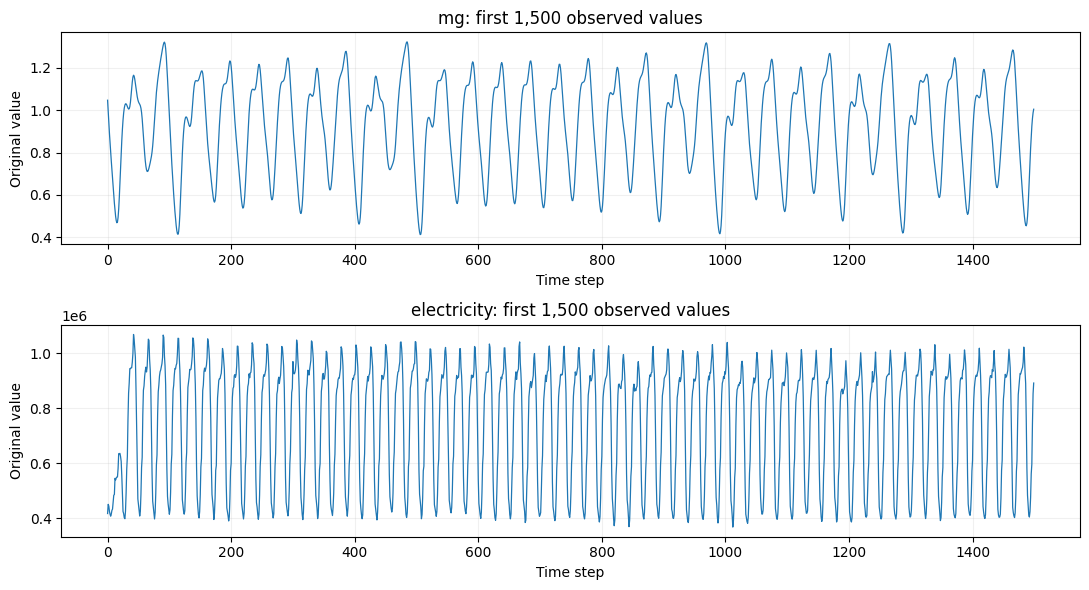

In [43]:
from experiment_engine import prepare_data, windows_for
META = prepare_data(CFG)
display(pd.DataFrame([{'Dataset':k,**v} for k,v in META.items()]))
fig,axes=plt.subplots(len(CFG['DATASETS']),1,figsize=(11,3.0*len(CFG['DATASETS'])),squeeze=False)
for idx,name in enumerate(CFG['DATASETS']):
    values=np.load(RUN_DIR/'data'/f'{name}.npy')
    view=values[:min(len(values),1500)]
    ax=axes[idx,0];ax.plot(view,linewidth=.9)
    ax.set(title=f'{name}: first {len(view):,} observed values',xlabel='Time step',ylabel='Original value')
    ax.grid(alpha=.18)
plt.tight_layout();plt.show()

## 9. Understand the data splits and why leakage is dangerous

For example, on a 50,000-point Mackey–Glass series:
- Train: earlier 35,000 points.
- Validation: next 7,500 points (used for learning-rate choice and model selection).
- Test: final 7,500 points (held out for final reporting).

Each training sample uses 100 observed steps (`context`) and the *next* 100 future steps (`target`). Validation and test samples are restricted to their own splits. The mean/std are calculated only from the training partition.

**Question to understand:** If we normalize using all test readings, we have accidentally given the model information about the future data distribution. That is why we fit the scaler on training only.

In [44]:
rows=[]
for d in CFG['DATASETS']:
    train_ds,val_ds,test_ds=windows_for(CFG,d)
    rows.append(dict(dataset=d,train_hours=train_ds.b-train_ds.a,
                     val_hours=val_ds.b-val_ds.a,test_hours=test_ds.b-test_ds.a,
                     train_windows=len(train_ds.origins),val_forecast_origins=len(val_ds.origins),
                     test_forecast_origins=len(test_ds.origins),
                     train_mean=train_ds.mean,train_std=train_ds.std))
display(pd.DataFrame(rows))
ctx, tgt=next(train_ds.batches(min(4,CFG['BATCH_SIZE'])))
print('Model input shape [batch, context, variables]:', tuple(ctx.shape))
print('Future truth shape [batch, horizon, variables]:', tuple(tgt.shape))

,dataset,train_hours,val_hours,test_hours,train_windows,val_forecast_origins,test_forecast_origins,train_mean,train_std
0,mg,35000,7500,7500,512,48,48,0.929669,0.225818
1,electricity,18412,3946,3946,512,38,38,819406.881327,320195.907860


Model input shape [batch, context, variables]: (4, 100, 1)
Future truth shape [batch, horizon, variables]: (4, 100, 1)


## 10. How are model sizes matched?

An LSTM has four gated transforms, GRU has three, and vanilla RNN has one. Assigning all of them the same hidden width gives substantially different numbers of trainable weights.

Here we approximate-match **trainable parameter counts** to a 64-unit RNN (smoke mode uses 16). We report both width and count. ESN is kept separate because the number of *learned readout coefficients* is not comparable to training its reservoir.

In [45]:
from experiment_engine import ForecastNet, params
hidden=match_hidden_sizes(CFG['RNN_HIDDEN'])
display(pd.DataFrame([
    {'Model':a,'Hidden width':hidden[a], 'Trainable parameters':params(ForecastNet(a,hidden[a]))}
    for a in ['RNN','LSTM','GRU']]))

,Model,Hidden width,Trainable parameters
0,RNN,64,4353
1,LSTM,31,4248
2,GRU,36,4249


## 11. Sanity check: a model-free baseline

Suppose we assume that the last observed value stays constant for all 100 future steps. This is called **persistence forecasting**. It needs no neural network.

Every trained model should be compared with this simple baseline. If an RNN cannot beat it, we must not hide that result.

In [46]:
from experiment_engine import persistence
baseline=[]
for d in CFG['DATASETS']:
    _,_,test_ds=windows_for(CFG,d)
    baseline.append({'dataset':d,**persistence(test_ds)})
display(pd.DataFrame(baseline))

,dataset,rmse_rollout,rmse_rollout_norm,rmse_1,rmse_20,rmse_50,rmse_100
0,mg,0.281230,1.245379,0.034500,0.346310,0.162693,0.150766
1,electricity,443207.597718,1.384176,103058.307335,341128.594674,203745.528032,337206.001961


## 12. Pilot benchmark: estimate one batch's training cost

Before launching 342 experiments, time one representative mini-batch. This is **not an experimental finding** and not an exact prediction of the full runtime; it simply checks that the computation works and gives a rough scale.

In [47]:
from experiment_engine import tbptt_batch, gpu_sync
DEVICE0 = 'cuda:0' if torch.cuda.is_available() else 'cpu'
train_ds,_,_=windows_for(CFG,CFG['DATASETS'][0])
small_ctx,small_y=next(train_ds.batches(min(CFG['BATCH_SIZE'],8)))
small_ctx,small_y=small_ctx.to(DEVICE0),small_y.to(DEVICE0)
model=ForecastNet('LSTM',match_hidden_sizes(CFG['RNN_HIDDEN'])['LSTM']).to(DEVICE0)
opt=torch.optim.Adam(model.parameters(),lr=.001)
gpu_sync(DEVICE0);t0=time.perf_counter()
batch_loss, grad_norm=tbptt_batch(model,small_ctx,small_y,opt,20,True,'always',1.,DEVICE0)
gpu_sync(DEVICE0)
print(f'Pilot LSTM minibatch: {time.perf_counter()-t0:.3f} seconds; '
      f'training MSE={batch_loss:.4f}; preclip gradient norm={grad_norm:.3f}')
del model,opt
if DEVICE0.startswith('cuda'):torch.cuda.empty_cache()

Pilot LSTM minibatch: 2.555 seconds; training MSE=1.0271; preclip gradient norm=0.741


## 13. Run architecture-specific hyperparameter tuning

For `minimum` and `full`, tune **five learning rates for each architecture/dataset pair** using validation free-running RMSE. RNN/GRU/LSTM use the same candidate learning rates and the same short tuning budget. ESNs use a five-candidate preset involving spectral radius, leak rate and ridge penalty, tuned on a 200-node reservoir, then held fixed for the reservoir-size sweep.

**Rigor:** Only validation results select hyperparameters. No future test target is fed back into forecasting. The tuning trials are **extra** compute beyond the main 342 runs; their chosen settings and costs are logged in `tuning/`.

**Dual GPU:** We launch one independent worker on `cuda:0` and one on `cuda:1`; each processes its assigned experiments. For smaller recurrent models, this avoids distributed synchronization overhead.

In [48]:
# General-purpose Kaggle worker launcher. The engine is a standalone file written
# above, because Python subprocesses cannot reliably import notebook cell state.

def launch_workers(mode):
    n_gpu = torch.cuda.device_count()
    if PRESET!='smoke' and n_gpu==0:
        raise RuntimeError('For the full experiments, enable Kaggle GPU T4 ×2 first.')
    n_workers = min(2,n_gpu) if n_gpu else 1
    print(f'Launching {n_workers} independent workers for {mode}.')
    processes=[]; logs=[]
    for wid in range(n_workers):
        device=f'cuda:{wid}' if n_gpu else 'cpu'
        args=[sys.executable,'-u',str(PROJECT_DIR/'experiment_engine.py'),
              '--config',str(CONFIG_PATH),'--mode',mode,
              '--worker-id',str(wid),'--workers',str(n_workers),'--device',device]
        logpath=RUN_DIR/f'{mode}_worker_{wid}.log'
        fp=open(logpath,'a',encoding='utf-8')
        p=subprocess.Popen(args,stdout=fp,stderr=subprocess.STDOUT,cwd=PROJECT_DIR)
        processes.append((p,fp));logs.append(logpath)
    last=-1
    while any(p.poll() is None for p,_ in processes):
        if mode=='run':
            n=len(list((RUN_DIR/'runs').glob('*.json'))) if (RUN_DIR/'runs').exists() else 0
            if n!=last:
                print(f'  completed/recorded configurations: {n}/{len(experiment_grid(CFG))}',flush=True)
                last=n
        time.sleep(4)
    for p,fp in processes: fp.close()
    bad=[(i,p.returncode) for i,(p,_) in enumerate(processes) if p.returncode!=0]
    for i,path in enumerate(logs):
        tail=path.read_text(errors='replace').splitlines()[-4:]
        print(f'Worker {i} last messages:', ' | '.join(tail) if tail else '(none)')
    if bad: raise RuntimeError(f'One or more experiment workers exited unsuccessfully: {bad}. Read log files under {RUN_DIR}.')
    return logs

if CFG['RUN_TUNING']:
    launch_workers('tune')
else:
    print('Tuning disabled in smoke mode; using the same default LR = 0.001.')

Launching 2 independent workers for tune.
Worker 0 last messages: [worker 0] tuning mg/RNN | [worker 0] tuning mg/GRU | [worker 0] tuning electricity/RNN | [worker 0] tuning electricity/GRU
Worker 1 last messages: [worker 1] tuning mg/LSTM | [worker 1] tuning mg/ESN | [worker 1] tuning electricity/LSTM | [worker 1] tuning electricity/ESN


## 14. Train everything — resumable experiment grid

This is the principal experiment. In FULL mode, it executes **all required architectures and training-factor combinations**:

`RNN / LSTM / GRU × (20, 50, full TBPTT) × (clip off/on) × (always/scheduled/never forcing) × (3 seeds) × (2 datasets)` plus ESN sizes 200/500/1000 and 3 seeds on each dataset.

For each model:
1. Use identical chronological partitions and observed/forecast lengths.
2. Train over the same capped set of origins and epoch budget.
3. Choose epoch/checkpoint using validation free-running RMSE.
4. Evaluate test once using that selected checkpoint (never teacher-forced).
5. Record RMSE by horizon, wall/train seconds, memory, gradient norms and divergence.
6. Save every result immediately. A failed run is recorded, not silently removed.

**Timing note:** Running small LSTMs may spend time in Python/autoregressive loops; two GPUs help throughput but do not halve every runtime. The notebook cannot guarantee all runs fit within one Kaggle session.

In [49]:
launch_workers('run')
print('Experiment runner finished for this session. Loading saved results next.')

Launching 2 independent workers for run.
  completed/recorded configurations: 0/342
  completed/recorded configurations: 2/342
  completed/recorded configurations: 4/342
  completed/recorded configurations: 5/342
  completed/recorded configurations: 6/342
  completed/recorded configurations: 8/342
  completed/recorded configurations: 9/342
  completed/recorded configurations: 10/342
  completed/recorded configurations: 12/342
  completed/recorded configurations: 13/342
  completed/recorded configurations: 14/342
  completed/recorded configurations: 16/342
  completed/recorded configurations: 18/342
  completed/recorded configurations: 19/342
  completed/recorded configurations: 20/342
  completed/recorded configurations: 22/342
  completed/recorded configurations: 24/342
  completed/recorded configurations: 25/342
  completed/recorded configurations: 26/342
  completed/recorded configurations: 28/342
  completed/recorded configurations: 29/342
  completed/recorded configurations: 30/34

## 15. Create the actual results, figures and statistical tests

The analysis chooses each trainable architecture's strongest TBPTT/clipping/forcing configuration **using average validation error over three seeds**. It then summarizes the corresponding held-out test results. ESN reservoir size is also selected using validation, not test.

It also attempts a **four-factor ANOVA** (architecture × TBPTT × clipping × forcing), adding seed as a blocking factor, only if all configurations are present. We use `log(1 + normalized 100-step rollout RMSE)` as the outcome. ANOVA does not magically make three seeds sufficient for strong causal claims; interpret effect sizes and assumptions cautiously.

In [50]:
from analysis_report import generate, load_results
RUN_DIR=generate(CFG)
results=load_results(CFG)
display(results[['dataset','architecture','status','seed']].groupby(['dataset','architecture','status']).size().rename('runs').reset_index())

Results folder: /kaggle/working/BAI301_Kaggle_Run/results/exp_b8f83540bd67fab5
Expected experiments: 342 | Result files found: 342
Successful runs: 342 | Failed runs: 0


,dataset,architecture,status,runs
0,electricity,ESN,ok,9
1,electricity,GRU,ok,54
2,electricity,LSTM,ok,54
3,electricity,RNN,ok,54
4,mg,ESN,ok,9
5,mg,GRU,ok,54
6,mg,LSTM,ok,54
7,mg,RNN,ok,54


## 16. The tables for your IEEE Results section

**`validation_selected_models.csv`** reports only groups with all three seeds. **`all_runs.csv`** contains the entire grid and all individual measurements. **`anova_interactions.csv`** reports full interaction tests only when complete. ESNs are included separately.

In [51]:
for filename in ['validation_selected_models.csv','esn_selected_runs.csv',
                 'persistence_baselines.csv','anova_interactions.csv']:
    path=RUN_DIR/filename
    display(Markdown(f'### {filename}'))
    if path.exists():
        table=pd.read_csv(path)
        display(table.head(25))
    else:
        print('Not ready: this table requires more completed runs.')

### validation_selected_models.csv

,dataset,architecture,tbptt,clip,forcing,seeds,test_rmse_1_mean,test_rmse_1_sd,test_rmse_20_mean,test_rmse_20_sd,...,test_rmse_rollout_mean,test_rmse_rollout_sd,test_rmse_rollout_norm_mean,test_rmse_rollout_norm_sd,training_seconds_mean,training_seconds_sd,peak_gpu_memory_mb_mean,peak_gpu_memory_mb_sd,gradient_norm_mean_mean,gradient_norm_mean_sd
0,electricity,GRU,full,False,always,3,25860.345096,1978.439952,87145.929103,9414.076640,...,106248.353920,12379.370616,0.331823,0.038662,28.083507,0.256754,37.778320,0.0,0.122726,0.007038
1,electricity,LSTM,full,False,never,3,344121.648387,15975.110419,338273.940906,6289.609493,...,339095.809961,4902.509880,1.059026,0.015311,29.278560,0.508543,35.355957,0.0,0.168585,0.075706
2,electricity,RNN,full,True,scheduled,3,151004.124896,5814.040639,160104.486304,6648.572919,...,198400.659689,2353.725283,0.619623,0.007351,27.718095,0.343004,37.861816,0.0,2.205453,0.340973
3,mg,GRU,20,False,never,3,0.052689,0.009198,0.080092,0.018742,...,0.131844,0.009323,0.583851,0.041285,29.363771,0.274543,27.793945,0.0,0.747233,0.062859
4,mg,LSTM,full,True,scheduled,3,0.015339,0.004338,0.065145,0.018586,...,0.126091,0.013012,0.558371,0.057621,32.191297,0.049104,35.404297,0.0,2.372176,0.653436
5,mg,RNN,full,False,never,3,0.050278,0.007795,0.060235,0.002939,...,0.117636,0.003162,0.520932,0.014003,24.398270,0.135812,37.861328,0.0,10.285664,2.134580


### esn_selected_runs.csv

,dataset,architecture,tbptt,clip,forcing,seed,learning_rate,hidden_size,trainable_parameters,best_epoch,...,test_rmse_20,test_rmse_50,test_rmse_100,run_key,esn_size,esn_fit_states,esn_spectral_radius_target,esn_leak,esn_ridge,cpu_rss_postfit_mb
0,mg,ESN,NaN,NaN,NaN,42,NaN,NaN,1002,NaN,...,0.003033,0.003713,0.015687,2b0719538345a340,1000.0,6000.0,0.70,0.3,0.0001,6452.910156
1,mg,ESN,NaN,NaN,NaN,2026,NaN,NaN,1002,NaN,...,0.003093,0.002577,0.004702,310f222cf7cf2b8a,1000.0,6000.0,0.70,0.3,0.0001,6452.910156
2,mg,ESN,NaN,NaN,NaN,123,NaN,NaN,1002,NaN,...,0.002724,0.002872,0.009853,36c93b1880dce63f,1000.0,6000.0,0.70,0.3,0.0001,6463.589844
3,electricity,ESN,NaN,NaN,NaN,123,NaN,NaN,502,NaN,...,51794.388271,83150.182598,167861.874314,9407dfc0c762ca24,500.0,6000.0,1.05,0.3,0.0010,6463.589844
4,electricity,ESN,NaN,NaN,NaN,42,NaN,NaN,502,NaN,...,491143.210590,201135.336562,242564.648778,9861c263df86817e,500.0,6000.0,1.05,0.3,0.0010,6463.558594
5,electricity,ESN,NaN,NaN,NaN,2026,NaN,NaN,502,NaN,...,316265.678630,179178.480078,242793.061846,d81360da43c19e6e,500.0,6000.0,1.05,0.3,0.0010,6463.558594


### persistence_baselines.csv

,dataset,rmse_rollout,rmse_rollout_norm,rmse_1,rmse_20,rmse_50,rmse_100
0,mg,0.281230,1.245379,0.034500,0.346310,0.162693,0.150766
1,electricity,443207.597718,1.384176,103058.307335,341128.594674,203745.528032,337206.001961


### anova_interactions.csv

,dataset,status,effect,sum_sq,F,pvalue,df
0,electricity,ok,C(architecture),2.405263,296.629255,3.761920e-44,2.0
1,electricity,ok,C(tbptt),0.005474,0.675098,5.112818e-01,2.0
2,electricity,ok,C(clip),0.005436,1.340801,2.494950e-01,1.0
3,electricity,ok,C(forcing),0.237110,29.241660,7.704638e-11,2.0
4,electricity,ok,C(seed),0.024542,3.026688,5.268519e-02,2.0
5,electricity,ok,C(architecture):C(tbptt),0.009707,0.598553,6.644778e-01,4.0
6,electricity,ok,C(architecture):C(clip),0.010195,1.257293,2.886293e-01,2.0
7,electricity,ok,C(tbptt):C(clip),0.002974,0.366780,6.938379e-01,2.0
8,electricity,ok,C(architecture):C(forcing),0.290692,17.924828,2.869589e-11,4.0
9,electricity,ok,C(tbptt):C(forcing),0.009425,0.581194,6.769110e-01,4.0


## 17. Figures ready for the research paper

Plots come from actual test measurements. Depending on completed configs, the analysis can generate:
- RMSE vs forecast horizon (steps 1, 20, 50, 100)
- Accuracy vs training seconds
- Architecture × TBPTT heatmap

Plot absence is **not** silently replaced with an illustrative figure. If your run is incomplete, finish it first.

**electricity_accuracy_cost.png**

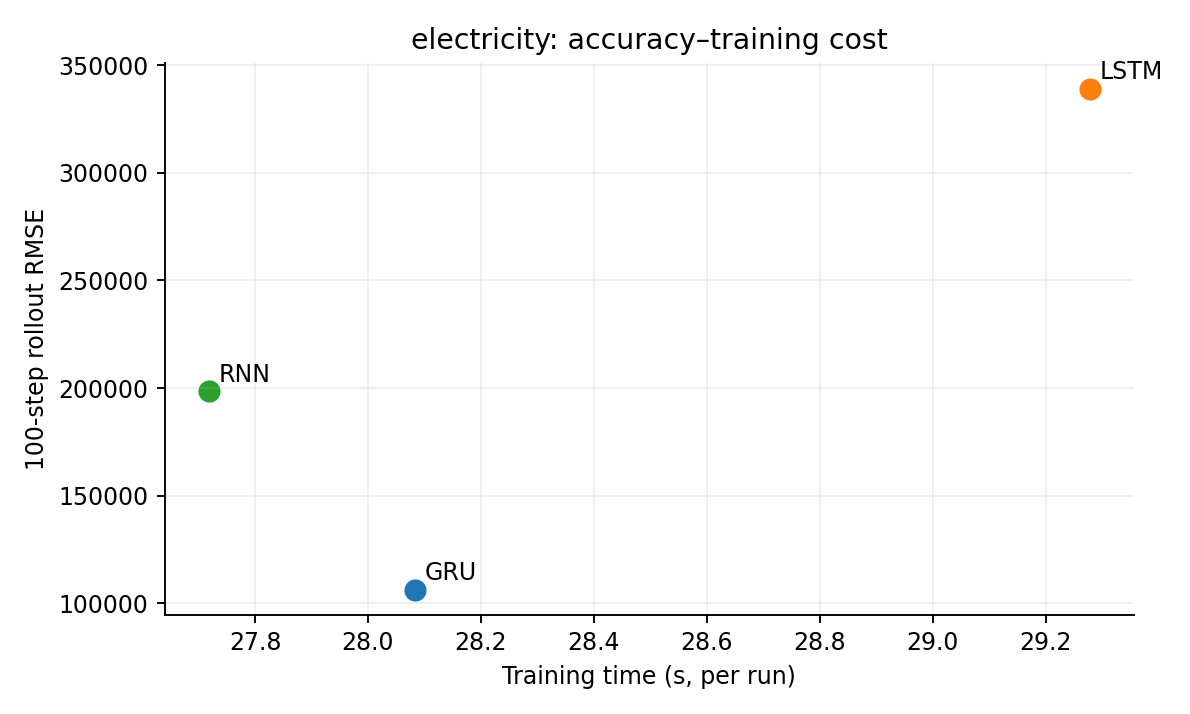

**electricity_esn_sweep.png**

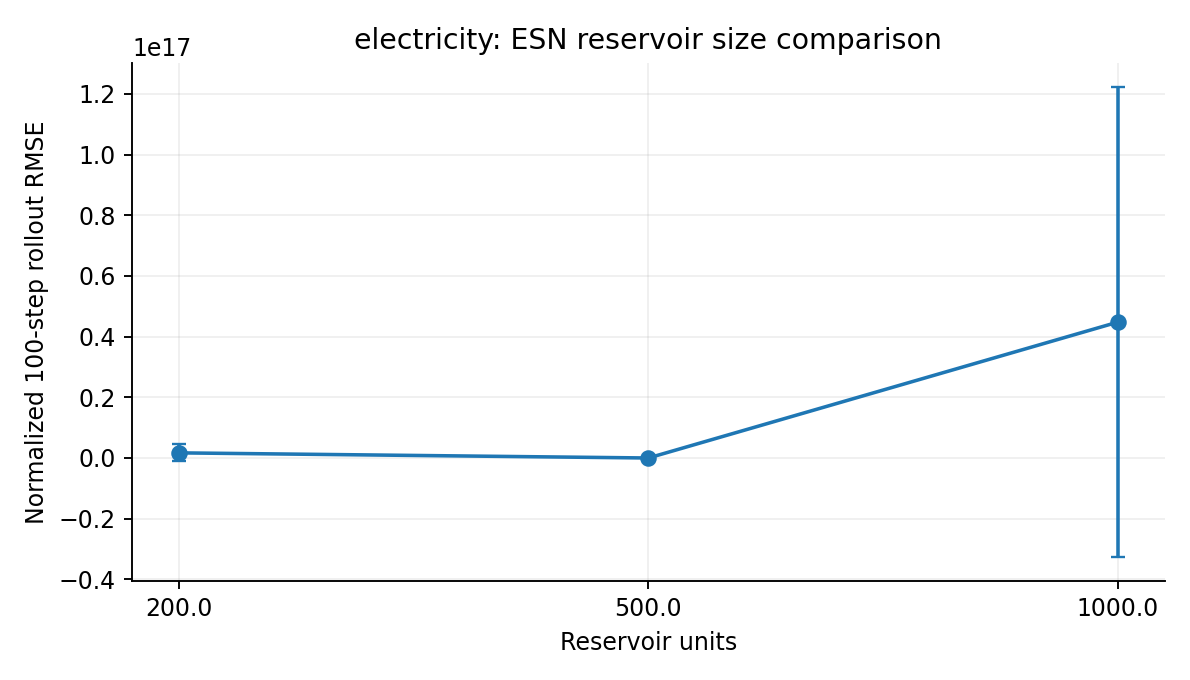

**electricity_gradient_clipping.png**

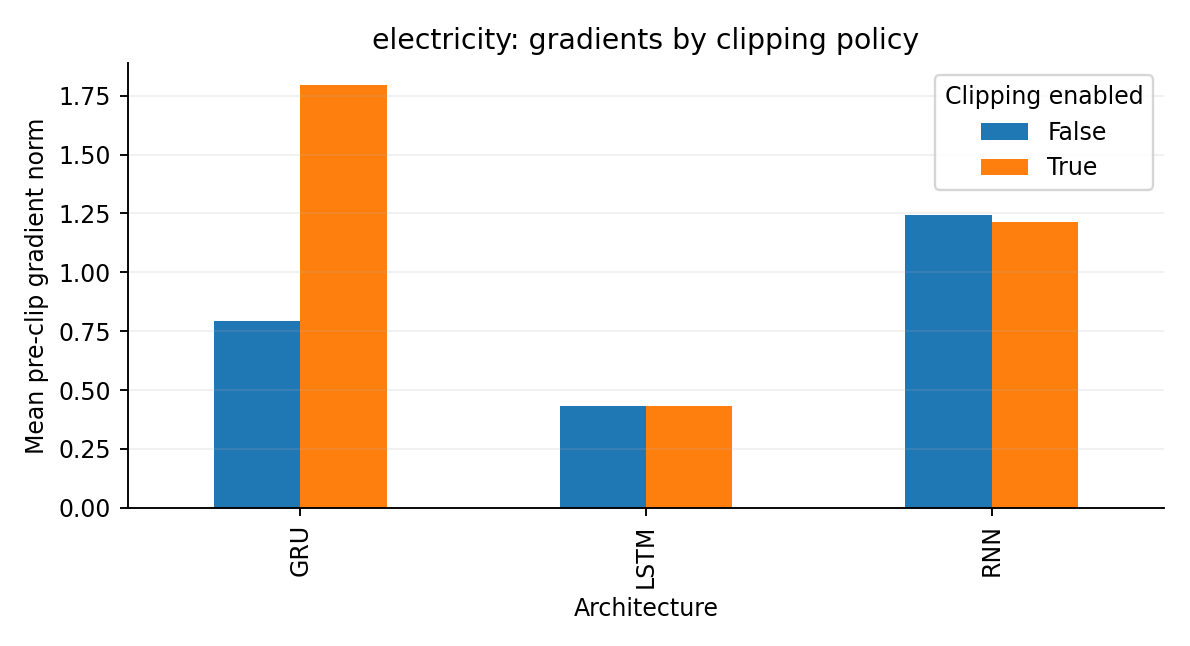

**electricity_horizon.png**

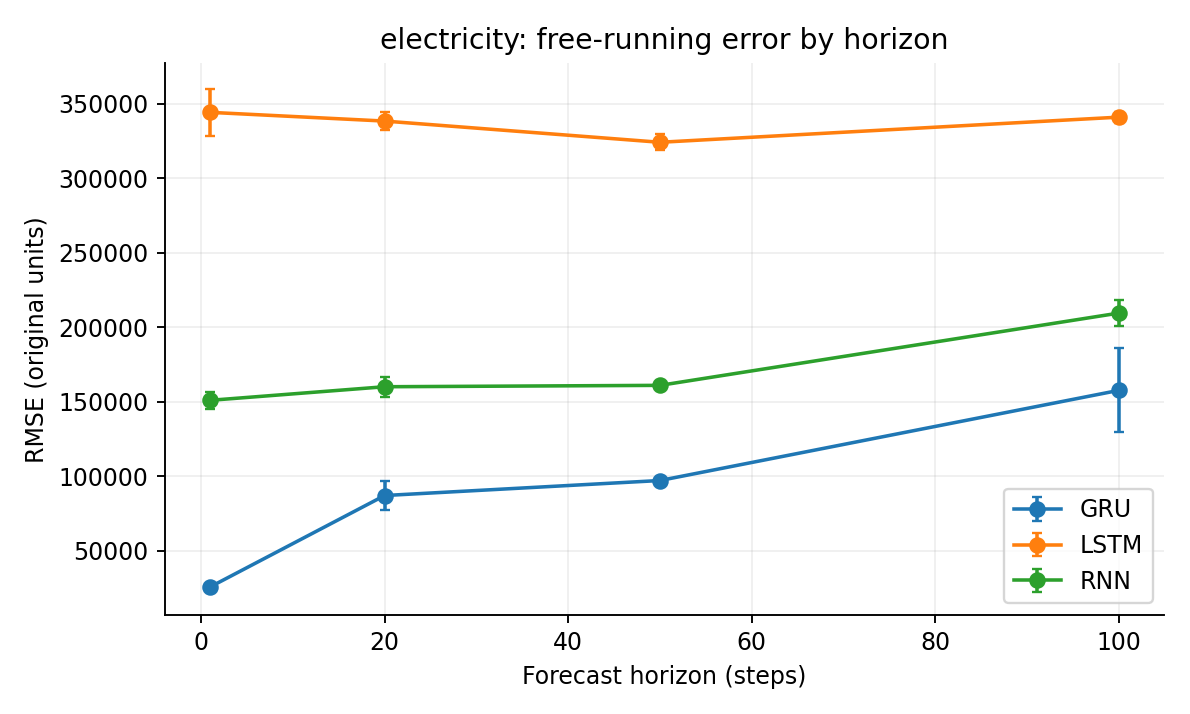

**electricity_tbptt_heatmap.png**

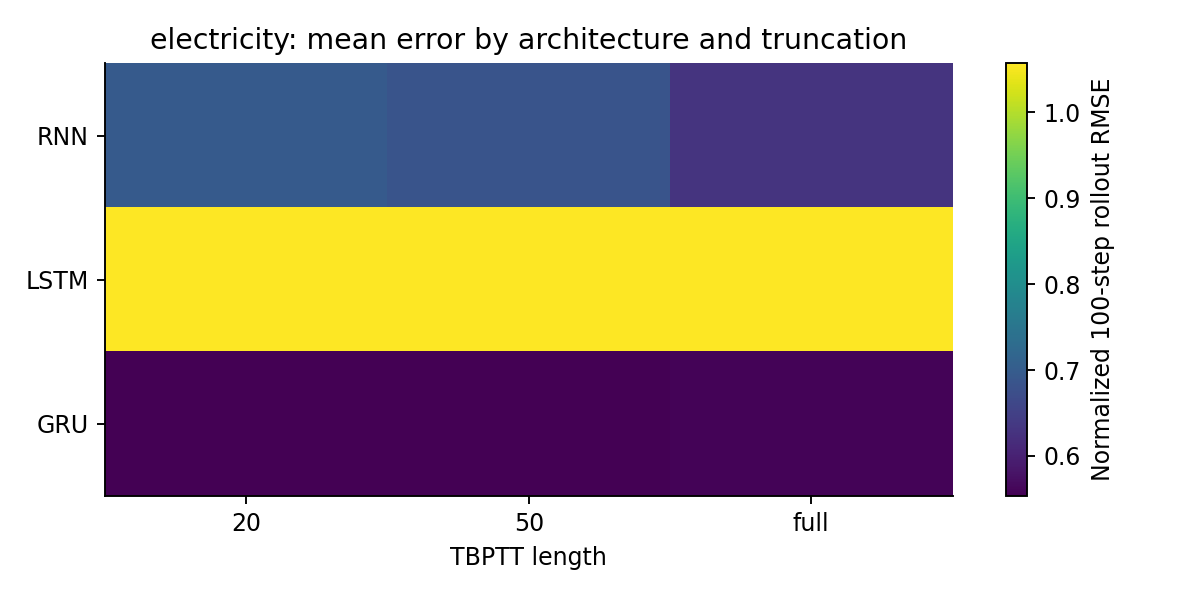

**electricity_teacher_forcing.png**

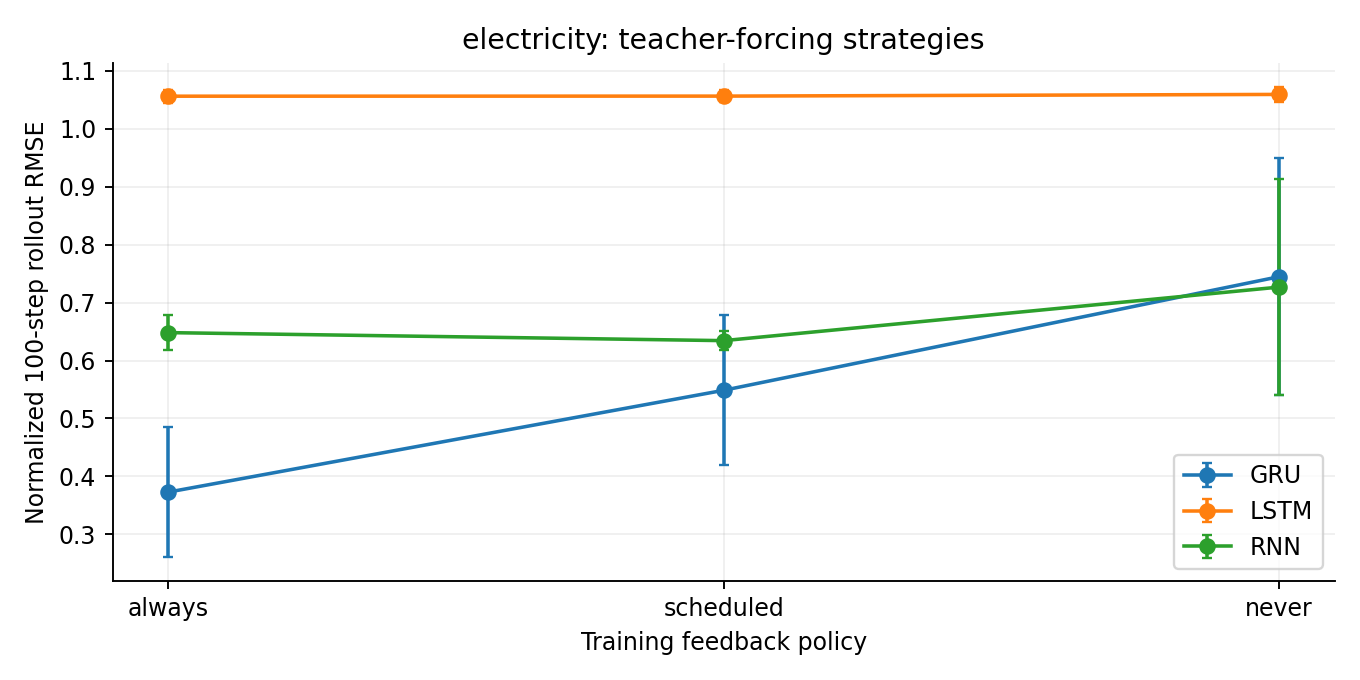

**mg_accuracy_cost.png**

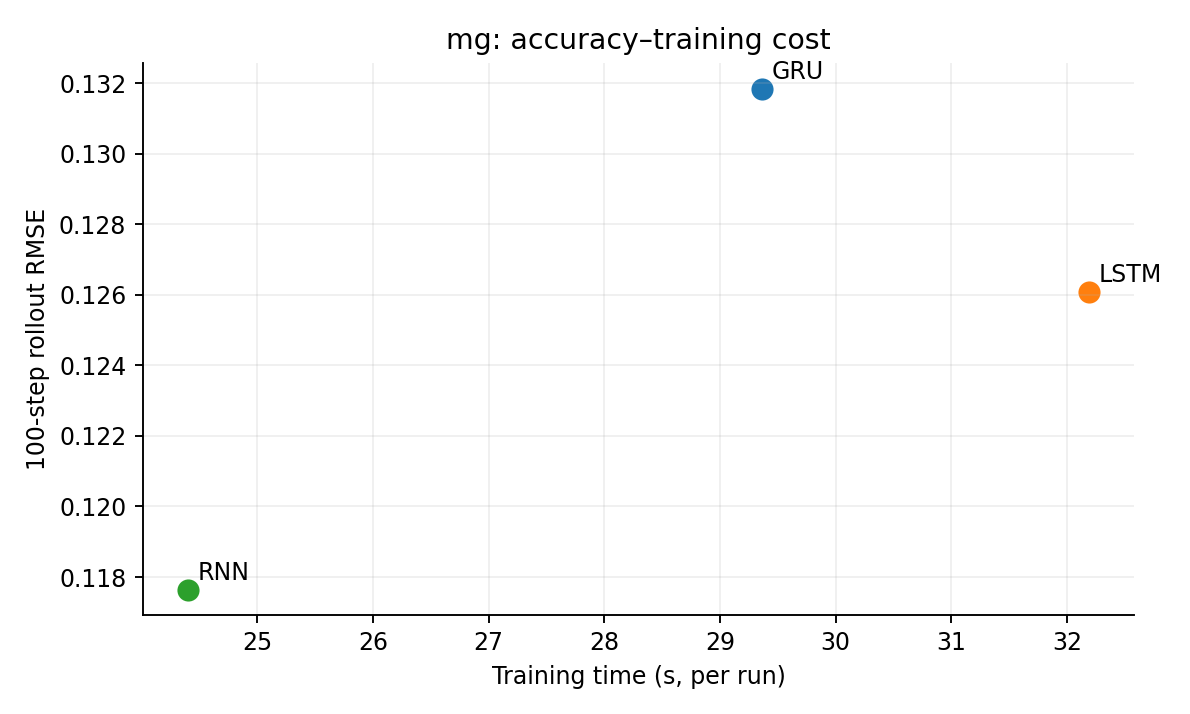

**mg_esn_sweep.png**

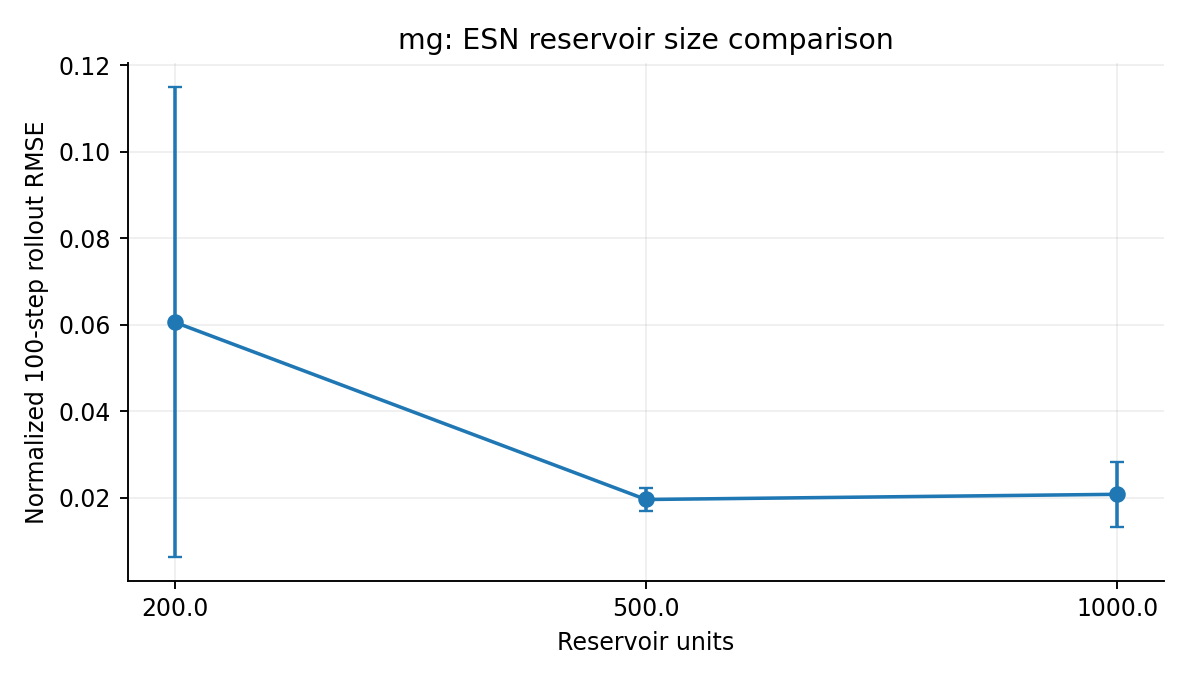

**mg_gradient_clipping.png**

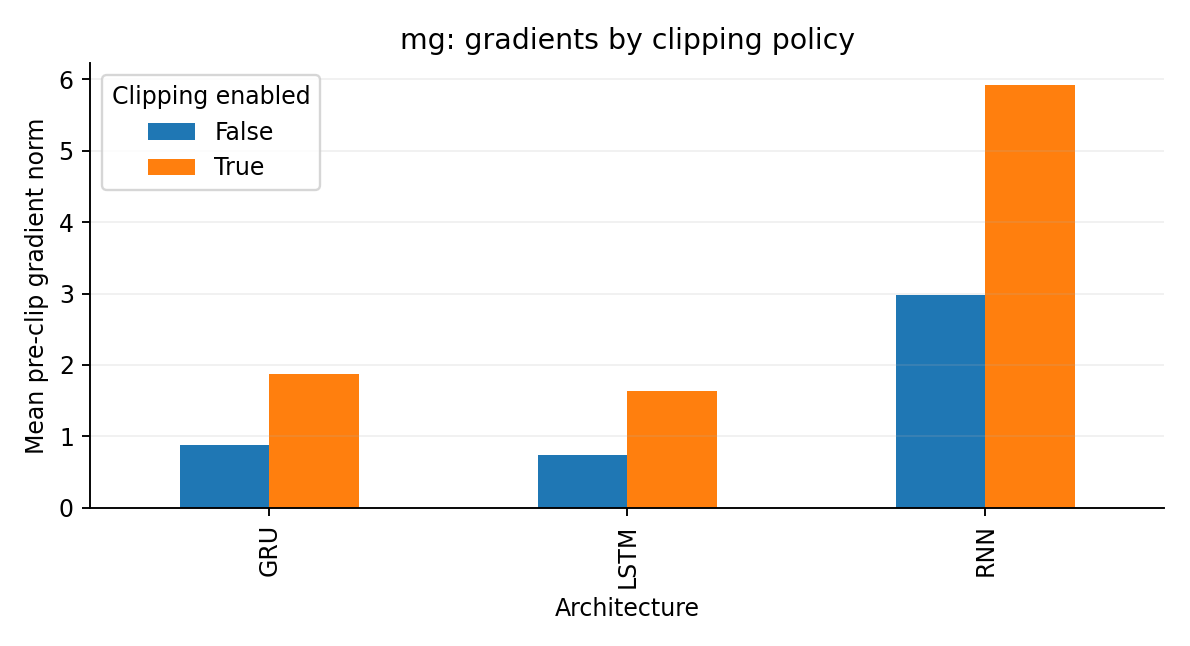

**mg_horizon.png**

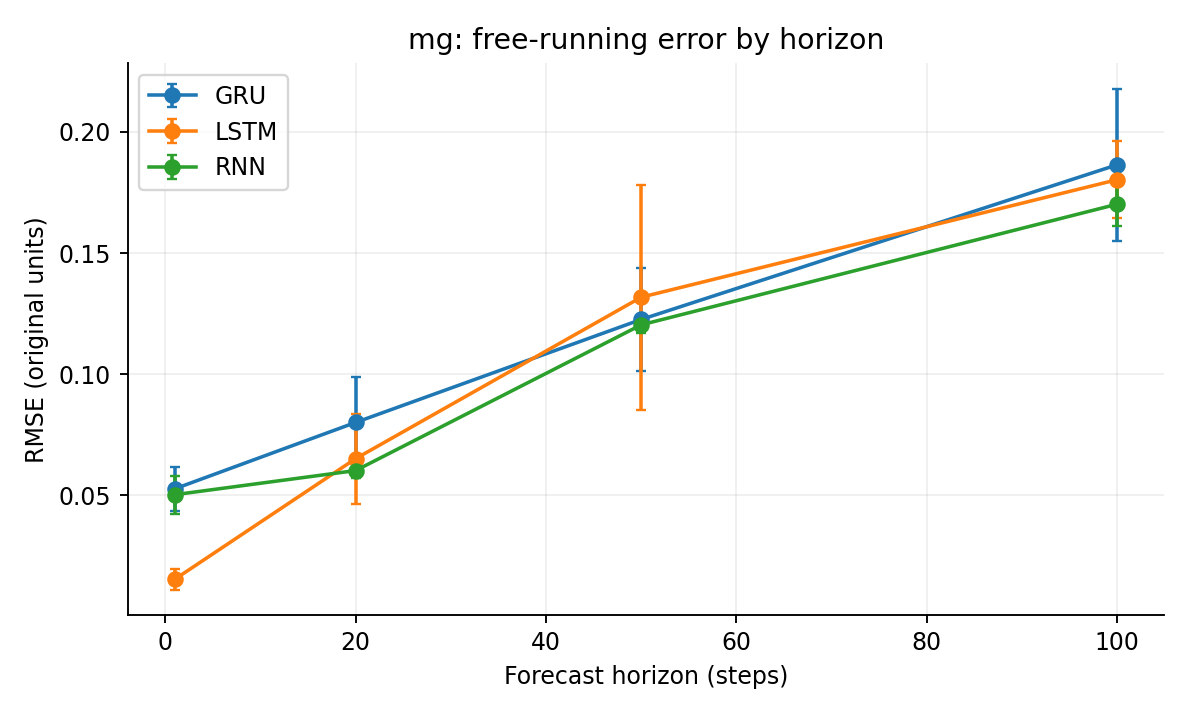

**mg_tbptt_heatmap.png**

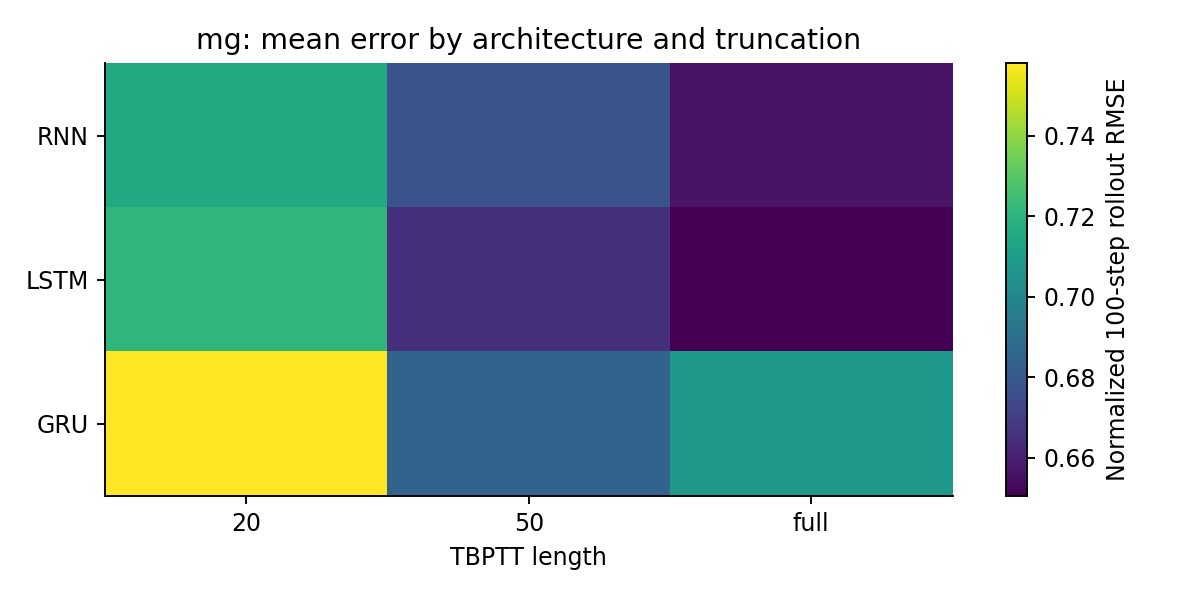

**mg_teacher_forcing.png**

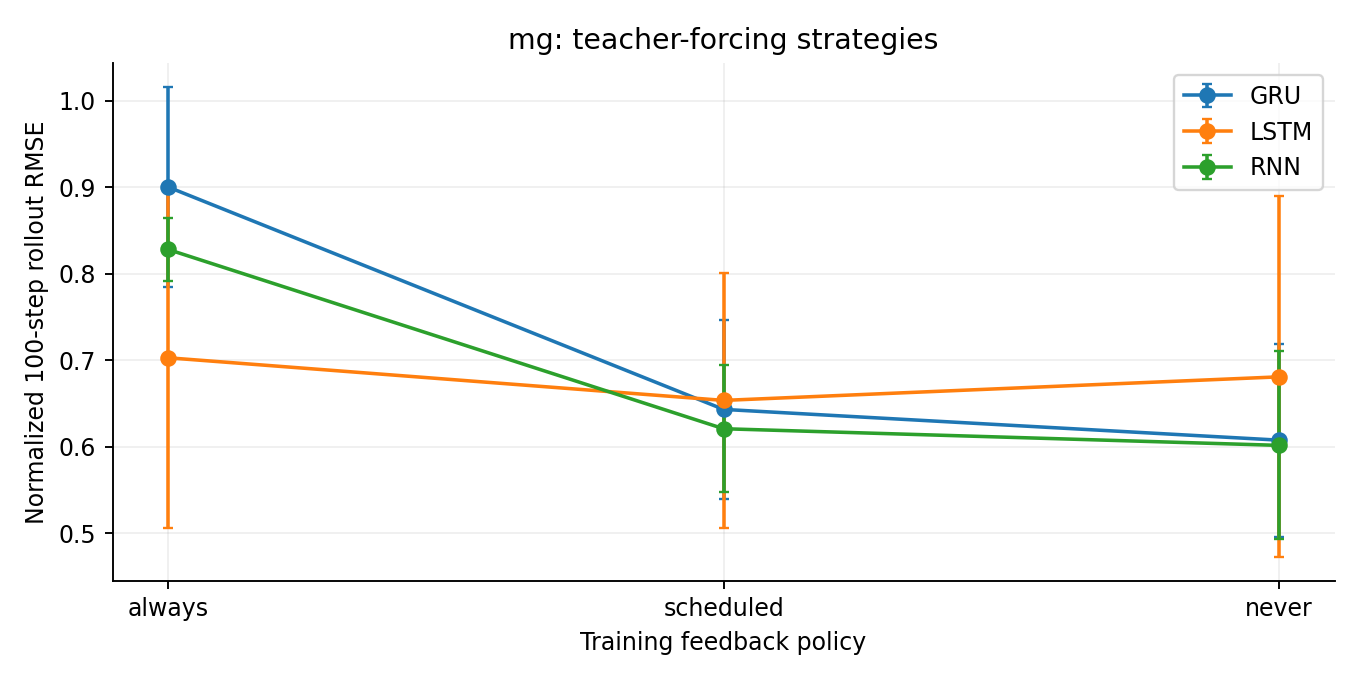

In [52]:
images=sorted((RUN_DIR/'figures').glob('*.png')) if (RUN_DIR/'figures').exists() else []
if not images:
    print('No eligible three-seed selected configurations yet; run full grid for paper figures.')
else:
    for picture in images:
        display(Markdown('**'+picture.name+'**'))
        display(Image(filename=str(picture)))

## 18. Extract paper-ready LaTeX and preserve the evidence

**`ieee_results_generated.tex`** is ready to `\input{}` into an IEEE two-column manuscript after the runs are complete. It is derived directly from the saved numerical results. The main IEEE manuscript must also update its Method section so it correctly describes this implementation's **forward-Euler Mackey–Glass generator, training origin cap, exact full-graph length and tuning protocol**.

Raw results and provenance are as important as the headline table: **do not submit a paper claiming measurements from experiments that have not finished.**

In [53]:
tex=RUN_DIR/'ieee_results_generated.tex'
print('IEEE LaTeX file:',tex)
print(tex.read_text()[:5000] if tex.exists() else 'Not available')
print('\n--- Summary ---')
print((RUN_DIR/'SUMMARY.md').read_text()[:6000])

IEEE LaTeX file: /kaggle/working/BAI301_Kaggle_Run/results/exp_b8f83540bd67fab5/ieee_results_generated.tex
% GENERATED FROM REAL RUN LOGS. Never hand-enter invented results.
% This table selects RNN/LSTM/GRU settings using validation-only RMSE.
\begin{table*}[t]
\centering
\caption{Held-out free-running forecasting performance (mean $\pm$ SD over three seeds).}
\begin{tabular}{llrrrr}
\hline
Dataset & Model & RMSE@1 & RMSE@100 & Rollout RMSE & Train time (s) \\
\hline
electricity & GRU & 2.59e+04 $\pm$ 2e+03 & 1.58e+05 $\pm$ 2.8e+04 & 1.06e+05 $\pm$ 1.2e+04 & 28.1 $\pm$ 0.26 \\
electricity & LSTM & 3.44e+05 $\pm$ 1.6e+04 & 3.41e+05 $\pm$ 3.8e+03 & 3.39e+05 $\pm$ 4.9e+03 & 29.3 $\pm$ 0.51 \\
electricity & RNN & 1.51e+05 $\pm$ 5.8e+03 & 2.1e+05 $\pm$ 8.5e+03 & 1.98e+05 $\pm$ 2.4e+03 & 27.7 $\pm$ 0.34 \\
electricity & ESN (500.0) & 2.42e+04 $\pm$ 9.2e+02 & 2.18e+05 $\pm$ 4.3e+04 & 2.46e+05 $\pm$ 1.4e+05 & 0.497 $\pm$ 0.19 \\
\hline
mg & GRU & 0.0527 $\pm$ 0.0092 & 0.186 $\pm$ 0.031 & 0.13

## 19. Download and archive the entire experiment

The ZIP contains data (including source metadata and hashes), tuning choices, epoch histories, every result including failed runs, paper tables, PNG figures, and environment information. Your downloaded Kaggle notebook is separate and already contains both source scripts.

**To resume another day:** preserve the original `results/exp_<id>` directory and restore it under the same `PROJECT_DIR/results/` before running. Keep the same `CFG` settings so the experiment ID remains identical.

In [54]:
ARCHIVE_BASE=PROJECT_DIR/f'BAI301_{PRESET}_results'
archive=shutil.make_archive(str(ARCHIVE_BASE),'zip',root_dir=str(RUN_DIR.parent),base_dir=RUN_DIR.name)
print('Archive ready:',archive)
display(FileLink(archive))
print('Source and output folder:',PROJECT_DIR)

Archive ready: /kaggle/working/BAI301_Kaggle_Run/BAI301_full_results.zip


/kaggle/working/BAI301_Kaggle_Run/BAI301_full_results.zip

Source and output folder: /kaggle/working/BAI301_Kaggle_Run


## 20. How to interpret results (do not assume an outcome)

1. **RQ1 — Architecture and training interactions:** Inspect `anova_interactions.csv` and the heatmap. A small p-value alone is not enough. Read the effect size and how much runs vary by seed. Compare datasets separately.
2. **RQ2 — Ranking changes:** Select configurations using validation only. Compare the held-out `RMSE@1` ranking with the *aggregate 100-step free-running* RMSE ranking. If they agree, report that honestly.
3. **RQ3 — Cost:** Use `training_seconds` and GPU peak allocated MB for gradient-trained models. ESN fits a CPU readout and records CPU RSS instead — **do not pretend these are equivalent units or hardware**.
4. **RQ4 — ESN:** Check whether the validation-selected reservoir size reaches competitive error and how much CPU fitting time was required. Note differences in training regimes and tuning overhead.
5. **Sanity baseline:** Compare all models to the persistence forecast. It is possible a model performs worse than persistence on some horizons; keep that in your report.

### Checks before final IEEE submission
- All 324 neural runs and 18 ESN runs recorded, with three seeds and two datasets.
- Every failure retained and disclosed; resolve environment crashes and describe true optimization failures.
- Hyperparameter search documented, using only validation data.
- Mean ± SD shown correctly; no invented numbers.
- Raw logs, dataset source, hardware version, and code in repository.
- Actual manuscript text matches the implemented data generator and training window cap.
- Statistical interactions interpreted carefully; uncertainty and limitations included.

### Reading for the 2026 research extension (not part of these runs)
Burn-in is the observed sequence period used to establish recurrent memory before computing training loss. It is different from **Truncated Backpropagation Through Time (TBPTT)**, which limits the gradient history. The ICLR 2026 burn-in paper motivates a possible later study of their interactions — but this notebook deliberately **does not add burn-in** as a factor, preserving the coursework scope.